# Deteksi Trafik Malicious DoH sebagai Proof of Concept Deteksi Eksfiltrasi Data Berbasis Metadata Flow

Notebook final ini disusun runtut dari setup, preprocessing, evaluasi model, robustness analysis, sampai laporan eksperimen akhir.

## A. Dataset dan Preprocessing

Blok ini memuat konfigurasi eksperimen, pemuatan dataset, inspeksi awal, deteksi label, cleaning, seleksi fitur metadata flow, dan split train-test.

## 1. Setup dan Konfigurasi

In [1]:
# ==========================================================================
# 1. SETUP DAN KONFIGURASI EKSPERIMEN
# ==========================================================================

# --- Import pustaka standar Python ---
import json
import time
import warnings
from pathlib import Path

# --- Import pustaka pihak ketiga untuk manipulasi data dan visualisasi ---
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Import komponen machine learning dari scikit-learn ---
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Menyembunyikan peringatan non-kritis agar output eksperimen tetap bersih
warnings.filterwarnings("ignore")

# Mengatur gaya visualisasi matplotlib agar konsisten di seluruh notebook
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("default")

# --- Konstanta global eksperimen untuk menjamin reprodusibilitas ---
RANDOM_STATE = 42   # Seed acak untuk seluruh proses stokastik
TEST_SIZE = 0.2      # Proporsi data uji (20%)

# Daftar jalur kandidat berkas dataset (mendukung eksekusi dari root atau subfolder)
DATA_CANDIDATES = [
    Path("../data/BCCC-CIRA-CIC-DoHBrw-2020.csv"),
    Path("data/BCCC-CIRA-CIC-DoHBrw-2020.csv"),
]

# Daftar jalur kandidat direktori output untuk menyimpan artefak eksperimen
OUTPUT_CANDIDATES = [
    Path("../outputs"),
    Path("outputs"),
]

# Resolusi otomatis jalur dataset dan pembuatan direktori output
DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    DATA_CANDIDATES[0],
)
OUTPUT_DIR = (
    OUTPUT_CANDIDATES[0] if DATA_CANDIDATES[0].exists()
    else OUTPUT_CANDIDATES[1]
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Konfirmasi jalur aktif yang digunakan eksperimen
print(f"Dataset path : {DATA_PATH.resolve()}")
print(f"Output dir   : {OUTPUT_DIR.resolve()}")

Dataset path : D:\Skripsi\doh_exfiltration_skripsi\data\BCCC-CIRA-CIC-DoHBrw-2020.csv
Output dir   : D:\Skripsi\doh_exfiltration_skripsi\outputs


## 2. Load Dataset

In [2]:
# ==========================================================================
# 2. PEMUATAN DATASET
# ==========================================================================

# Membaca dataset BCCC-CIRA-CIC-DoHBrw-2020 dari berkas CSV
df_raw = pd.read_csv(DATA_PATH)

# Membersihkan spasi berlebih pada nama kolom agar tidak menyebabkan KeyError
df_raw.columns = df_raw.columns.str.strip()

# Menampilkan dimensi awal dataset (jumlah baris x kolom)
print(f"Shape dataset: {df_raw.shape}")

# Menampilkan 5 baris pertama untuk verifikasi struktur data
display(df_raw.head())

Shape dataset: (499106, 29)


,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label
0,353,80.890348,393,90.056393,469.209877,21.661253,82.888889,66.0,66,2.339046,...,0.534524,1.754601e-09,0.000042,0.000048,0.000019,0.000017,2.028699,0.737490,0.869641,Benign
1,1807,53.056709,4828,141.758602,145520.370987,381.471324,228.793103,76.0,68,1.201609,...,1.591559,5.348911e-05,0.007314,0.011523,0.015273,0.000016,-1.538407,1.573304,0.634722,Malicious
2,15000,479.536009,27719,886.150575,25949.480963,161.088426,135.186709,87.0,87,0.897396,...,0.670950,3.356292e-01,0.579335,0.139518,0.001976,0.000003,0.712241,0.240819,4.152404,Malicious
3,1755,58.193065,4617,153.125406,154088.445853,392.541007,245.112953,75.5,54,1.296268,...,2.029971,1.245935e+02,11.162146,5.011613,0.015778,0.012884,1.342708,0.447829,2.227258,Benign
4,618,3.491495,315,1.779646,319.410000,17.872045,93.300000,105.0,105,-1.963961,...,0.816362,2.975575e-09,0.000054,0.015507,0.015471,0.015466,1.986391,0.751146,0.003502,Benign


## 3. Inspeksi Dataset

In [3]:
# ==========================================================================
# 3. INSPEKSI AWAL DATASET
# ==========================================================================

# Membuat ringkasan per kolom: tipe data, jumlah & persentase missing, jumlah unik
inspection_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "unique": df_raw.nunique(dropna=True),
})

print("Ringkasan kolom:")
display(inspection_summary)

# Menghitung total baris duplikat identik dalam dataset
print(f"Duplikasi baris: {df_raw.duplicated().sum():,}")

# Menampilkan statistik deskriptif (mean, std, min, max, dll.) untuk seluruh kolom
display(df_raw.describe(include="all").T)

Ringkasan kolom:


,dtype,missing,missing_pct,unique
FlowBytesSent,int64,0,0.0,92881
FlowSentRate,float64,0,0.0,473663
FlowBytesReceived,int64,0,0.0,97046
FlowReceivedRate,float64,0,0.0,475526
PacketLengthVariance,float64,0,0.0,204248
PacketLengthStandardDeviation,float64,0,0.0,204015
PacketLengthMean,float64,0,0.0,196341
PacketLengthMedian,float64,0,0.0,32083
PacketLengthMode,int64,0,0.0,165
PacketLengthSkewFromMedian,float64,0,0.0,203906


Duplikasi baris: 7,115


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlowBytesSent,499106.0,NaN,NaN,NaN,40200.925483,143961.65579,55.0,618.0,1807.0,5542.0,8015359.0
FlowSentRate,499106.0,NaN,NaN,NaN,47339.147444,421275.12888,1.464903,54.107811,364.096931,3810.259664,23043478.26087
FlowBytesReceived,499106.0,NaN,NaN,NaN,42501.556227,139392.708614,54.0,476.0,4827.0,7888.0,7723184.0
FlowReceivedRate,499106.0,NaN,NaN,NaN,31668.292337,256680.472304,1.576245,141.812836,461.114551,4215.497773,7600000.0
PacketLengthVariance,499106.0,NaN,NaN,NaN,92635.84963,153493.758127,0.0,469.209877,18267.886503,141598.912222,1578115.36
PacketLengthStandardDeviation,499106.0,NaN,NaN,NaN,220.169083,210.141825,0.0,21.661253,135.142971,376.296309,1256.230616
PacketLengthMean,499106.0,NaN,NaN,NaN,173.159814,85.50649,56.0,92.0,152.488283,228.758621,689.8
PacketLengthMedian,499106.0,NaN,NaN,NaN,95.472702,32.99974,54.0,76.0,87.0,105.0,317.0
PacketLengthMode,499106.0,NaN,NaN,NaN,70.749953,14.830277,54.0,66.0,68.0,68.0,553.0
PacketLengthSkewFromMedian,499106.0,NaN,NaN,NaN,0.442934,1.551998,-10.0,0.199848,0.986397,1.201609,2.932375


## 4. Deteksi dan Encoding Label

In [4]:
# ==========================================================================
# 4. DETEKSI OTOMATIS DAN ENCODING KOLOM LABEL
# ==========================================================================


def detect_label_column(dataframe: pd.DataFrame) -> str:
    """Mendeteksi kolom target/label secara otomatis.

    Strategi pencarian:
      1. Mencocokkan nama kolom dengan daftar kandidat eksplisit.
      2. Jika tidak ditemukan, mencari kolom kategorial dengan kardinalitas rendah.
    """
    # Daftar nama kolom label yang umum digunakan pada dataset benchmark
    explicit_candidates = [
        "Label", "label", "Class", "class",
        "Target", "target", "Category", "category",
    ]
    for candidate in explicit_candidates:
        if candidate in dataframe.columns:
            return candidate

    # Fallback: kolom bertipe objek/kategori dengan jumlah nilai unik <= 20
    object_columns = (
        dataframe.select_dtypes(include=["object", "category", "bool"])
        .columns.tolist()
    )
    low_cardinality = [
        col for col in object_columns
        if 1 < dataframe[col].nunique(dropna=True) <= 20
    ]
    if low_cardinality:
        return low_cardinality[-1]

    raise ValueError(
        "Kolom label tidak ditemukan. "
        "Tambahkan nama label ke explicit_candidates."
    )


# Menjalankan deteksi kolom label pada dataset mentah
LABEL_COL = detect_label_column(df_raw)

print(f"Kolom label terdeteksi: {LABEL_COL}")

# Menampilkan distribusi frekuensi setiap kategori pada kolom label
display(
    df_raw[LABEL_COL]
    .value_counts(dropna=False)
    .rename("count")
    .to_frame()
)

Kolom label terdeteksi: Label


,count
Label,
Benign,249553
Malicious,249553


## 5. Cleaning dan Seleksi Fitur Metadata Flow

In [5]:
# ==========================================================================
# 5. PEMBERSIHAN DATA (CLEANING) DAN SELEKSI FITUR METADATA FLOW
# ==========================================================================

# Membuat salinan dataset agar data mentah asli tidak berubah
df = df_raw.copy()
initial_rows = len(df)

# Mengganti nilai tak-hingga (inf / -inf) menjadi NaN agar bisa ditangani imputer
df = df.replace([np.inf, -np.inf], np.nan)

# Menghapus baris yang kehilangan nilai pada kolom label target
df = df.dropna(subset=[LABEL_COL])

# Menghapus baris duplikat identik untuk mencegah data leakage dan bias
df = df.drop_duplicates().reset_index(drop=True)

# --- Seleksi fitur numerik (metadata flow) ---
# Mengambil seluruh kolom numerik kecuali kolom label
numeric_features = (
    df.drop(columns=[LABEL_COL])
    .select_dtypes(include=[np.number])
    .columns.tolist()
)

# Mengidentifikasi dan mengeliminasi fitur konstan (variansi nol)
# karena tidak memberikan daya diskriminatif pada model
constant_features = [
    col for col in numeric_features
    if df[col].nunique(dropna=True) <= 1
]
numeric_features = [
    col for col in numeric_features
    if col not in constant_features
]

# Membentuk matriks fitur independen (X)
X = df[numeric_features].copy()

# Membersihkan dan memformat string label target
y_raw = df[LABEL_COL].astype(str).str.strip()

# --- Encoding label untuk klasifikasi biner ---
label_encoder = LabelEncoder()
encoded_all = label_encoder.fit_transform(y_raw)
classes = label_encoder.classes_.tolist()

# Memastikan dataset memang bersifat biner (dua kelas)
if len(classes) != 2:
    raise ValueError(
        f"Pipeline ini disiapkan untuk klasifikasi biner. "
        f"Kelas ditemukan: {classes}"
    )

# Memetakan kelas positif (malicious/eksfiltrasi) berdasarkan kata kunci
positive_keywords = ["malicious", "attack", "exfil", "tunnel", "botnet"]
positive_class = next(
    (cls for cls in classes
     if any(kw in cls.lower() for kw in positive_keywords)),
    classes[1],
)
negative_class = next(cls for cls in classes if cls != positive_class)

# Mengonversi label menjadi integer biner (0 = Benign, 1 = Malicious)
y = (y_raw == positive_class).astype(int)

# --- Ringkasan hasil proses cleaning ---
cleaning_summary = {
    "initial_rows": int(initial_rows),
    "rows_after_cleaning": int(len(df)),
    "removed_rows": int(initial_rows - len(df)),
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
    "n_numeric_features": int(len(numeric_features)),
    "constant_features_removed": constant_features,
}

print(json.dumps(cleaning_summary, indent=2))

# Menampilkan sampel fitur metadata yang telah dibersihkan
display(X.head())

{
  "initial_rows": 499106,
  "rows_after_cleaning": 491991,
  "removed_rows": 7115,
  "label_column": "Label",
  "negative_class_0": "Benign",
  "positive_class_1": "Malicious",
  "n_numeric_features": 28,
  "constant_features_removed": []
}


,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeSkewFromMode,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation
0,353,80.890348,393,90.056393,469.209877,21.661253,82.888889,66.0,66,2.339046,...,1.870823,0.534524,1.754601e-09,0.000042,0.000048,0.000019,0.000017,2.028699,0.737490,0.869641
1,1807,53.056709,4828,141.758602,145520.370987,381.471324,228.793103,76.0,68,1.201609,...,0.628315,1.591559,5.348911e-05,0.007314,0.011523,0.015273,0.000016,-1.538407,1.573304,0.634722
2,15000,479.536009,27719,886.150575,25949.480963,161.088426,135.186709,87.0,87,0.897396,...,1.490425,0.670950,3.356292e-01,0.579335,0.139518,0.001976,0.000003,0.712241,0.240819,4.152404
3,1755,58.193065,4617,153.125406,154088.445853,392.541007,245.112953,75.5,54,1.296268,...,0.488805,2.029971,1.245935e+02,11.162146,5.011613,0.015778,0.012884,1.342708,0.447829,2.227258
4,618,3.491495,315,1.779646,319.410000,17.872045,93.300000,105.0,105,-1.963961,...,1.224947,0.816362,2.975575e-09,0.000054,0.015507,0.015471,0.015466,1.986391,0.751146,0.003502


## 6. Split Data Train-Test

In [6]:
# ==========================================================================
# 6. PEMBAGIAN DATA LATIH DAN DATA UJI (TRAIN-TEST SPLIT)
# ==========================================================================

# Melakukan stratified random split untuk menjaga proporsi kelas
# pada data latih dan data uji agar tetap representatif
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,        # 20% untuk data uji
    random_state=RANDOM_STATE,  # Seed reprodusibilitas
    stratify=y,                 # Stratifikasi berdasarkan label target
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape : {X_test.shape}")

# Menampilkan proporsi distribusi label pada data latih
print("Distribusi label train:")
display(
    y_train.value_counts(normalize=True)
    .rename({0: negative_class, 1: positive_class})
    .to_frame("ratio")
)

# Menampilkan proporsi distribusi label pada data uji
print("Distribusi label test:")
display(
    y_test.value_counts(normalize=True)
    .rename({0: negative_class, 1: positive_class})
    .to_frame("ratio")
)

Train shape: (393592, 28)
Test shape : (98399, 28)
Distribusi label train:


,ratio
Label,
Malicious,0.5072
Benign,0.4928


Distribusi label test:


,ratio
Label,
Malicious,0.5072
Benign,0.4928


## B. Training dan Evaluasi Utama

Blok ini memuat training model, evaluasi default threshold, confusion matrix, kurva evaluasi utama, dan feature importance.

## 7. Training Model

In [7]:
# ==========================================================================
# 7. KONFIGURASI PIPELINE DAN PELATIHAN MODEL
# ==========================================================================
#
# Catatan arsitektur pipeline:
#   - SimpleImputer(strategy="median") digunakan pada SEMUA pipeline untuk
#     menangani kemungkinan missing values secara robust.
#   - StandardScaler() HANYA disertakan pada Logistic Regression karena
#     model linear sensitif terhadap perbedaan skala antar fitur.
#   - Random Forest dan AdaBoost TIDAK menyertakan StandardScaler karena
#     model berbasis pohon keputusan (tree-based models) bersifat invariant
#     terhadap transformasi skala monotonik (monotonic feature scaling)
#     sehingga tidak memerlukan normalisasi maupun standardisasi fitur.

models = {
    # --- Pipeline Logistic Regression (memerlukan StandardScaler) ---
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),

    # --- Pipeline Random Forest (tanpa StandardScaler) ---
    # Tree-based model: invariant terhadap skala fitur monotonik,
    # sehingga StandardScaler tidak diperlukan.
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        )),
    ]),

    # --- Pipeline AdaBoost (tanpa StandardScaler) ---
    # Tree-based model: invariant terhadap skala fitur monotonik,
    # sehingga StandardScaler tidak diperlukan.
    "AdaBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", AdaBoostClassifier(
            n_estimators=200,
            learning_rate=0.5,
            random_state=RANDOM_STATE,
        )),
    ]),
}

# Kamus untuk menyimpan model terlatih dan durasi pelatihan
trained_models = {}
train_times = {}

# Iterasi pelatihan untuk setiap pipeline model
for model_name, model in models.items():
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start_time

    train_times[model_name] = elapsed
    trained_models[model_name] = model
    print(f"{model_name} selesai dilatih dalam {elapsed:.4f} detik")

Logistic Regression selesai dilatih dalam 3.6858 detik
Random Forest selesai dilatih dalam 76.6177 detik
AdaBoost selesai dilatih dalam 223.4601 detik


## 8. Evaluasi Model Default Threshold

In [9]:
def get_positive_scores(model, features: pd.DataFrame) -> np.ndarray:
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(features)
        return (scores - scores.min()) / (scores.max() - scores.min())
    return model.predict(features)


def evaluate_binary_classifier(model_name: str, model, X_eval: pd.DataFrame, y_eval: pd.Series) -> dict:
    start_time = time.perf_counter()
    y_score = get_positive_scores(model, X_eval)
    y_pred = (y_score >= 0.5).astype(int)
    inference_time = time.perf_counter() - start_time

    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred, labels=[0, 1]).ravel()
    fpr_value = fp / (fp + tn) if (fp + tn) else 0.0
    throughput = len(X_eval) / inference_time if inference_time > 0 else np.inf

    return {
        "model": model_name,
        "accuracy": accuracy_score(y_eval, y_pred),
        "precision": precision_score(y_eval, y_pred, zero_division=0),
        "recall_tpr": recall_score(y_eval, y_pred, zero_division=0),
        "f1_score": f1_score(y_eval, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, y_score),
        "fpr": fpr_value,
        "training_time_sec": train_times[model_name],
        "inference_time_sec": inference_time,
        "throughput_rows_per_sec": throughput,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "y_score": y_score,
        "y_pred": y_pred,
    }


evaluation_records = [
    evaluate_binary_classifier(model_name, model, X_test, y_test)
    for model_name, model in trained_models.items()
]

metrics_columns = [
    "model", "accuracy", "precision", "recall_tpr", "f1_score", "roc_auc", "fpr",
    "training_time_sec", "inference_time_sec", "throughput_rows_per_sec", "tn", "fp", "fn", "tp",
]
metrics_df = pd.DataFrame(evaluation_records)[metrics_columns].sort_values(
    by=["roc_auc", "f1_score", "recall_tpr"], ascending=False
).reset_index(drop=True)

display(metrics_df)

,model,accuracy,precision,recall_tpr,f1_score,roc_auc,fpr,training_time_sec,inference_time_sec,throughput_rows_per_sec,tn,fp,fn,tp
0,Random Forest,0.999868,0.999960,0.999780,0.999870,0.999999,0.000041,76.617726,0.268908,3.659210e+05,48489,2,11,49897
1,AdaBoost,0.998262,0.998597,0.997976,0.998286,0.999961,0.001444,223.460128,1.710995,5.750980e+04,48421,70,101,49807
2,Logistic Regression,0.901361,0.873222,0.942334,0.906463,0.958280,0.140810,3.685780,0.051032,1.928197e+06,41663,6828,2878,47030


## 9. Confusion Matrix

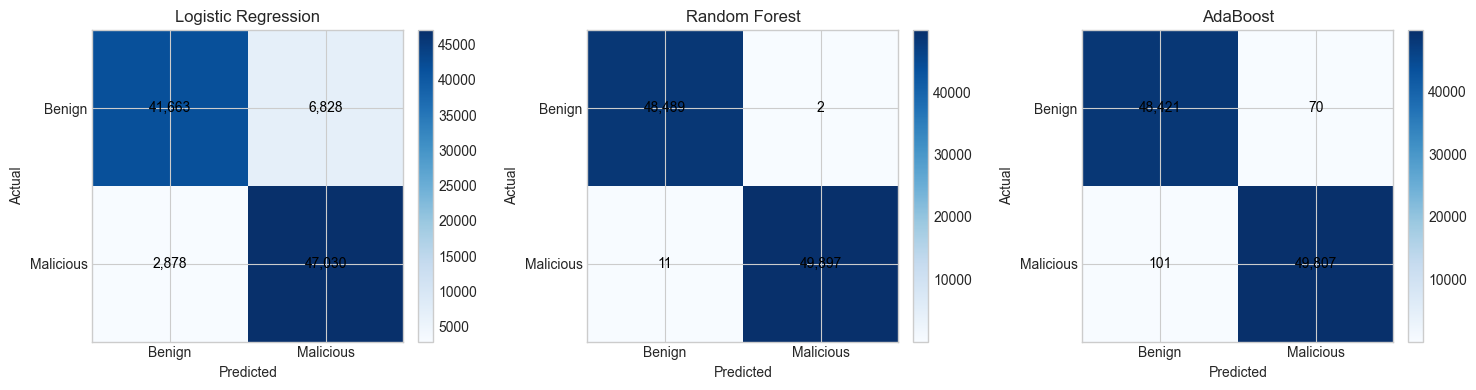

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\confusion_matrices.png


In [11]:
fig, axes = plt.subplots(1, len(evaluation_records), figsize=(5 * len(evaluation_records), 4))
if len(evaluation_records) == 1:
    axes = [axes]

for ax, record in zip(axes, evaluation_records):
    cm = np.array([[record["tn"], record["fp"]], [record["fn"], record["tp"]]])
    image = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], labels=[negative_class, positive_class])
    ax.set_yticks([0, 1], labels=[negative_class, positive_class])
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            ax.text(col, row, f"{cm[row, col]:,}", ha="center", va="center", color="black")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(record["model"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
confusion_matrix_path = OUTPUT_DIR / "confusion_matrices.png"
plt.savefig(confusion_matrix_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_matrix_path.resolve()}")

## 10. Baseline ROC Curve

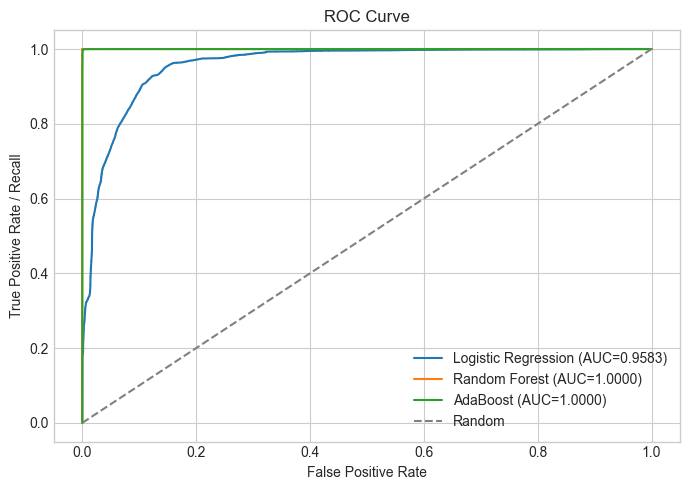

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\roc_curve.png


In [12]:
plt.figure(figsize=(7, 5))
roc_curves = {}

for record in evaluation_records:
    fpr_values, tpr_values, thresholds = roc_curve(y_test, record["y_score"])
    roc_curves[record["model"]] = {
        "fpr": fpr_values,
        "tpr": tpr_values,
        "thresholds": thresholds,
        "auc": auc(fpr_values, tpr_values),
    }
    plt.plot(fpr_values, tpr_values, label=f"{record['model']} (AUC={roc_curves[record['model']]['auc']:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
roc_curve_path = OUTPUT_DIR / "roc_curve.png"
plt.savefig(roc_curve_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {roc_curve_path.resolve()}")

## 11. Precision-Recall Curve and ROC Curve with Numeric AP Legend

Visualisasi Precision-Recall revisi menampilkan nilai Average Precision numerik pada legend untuk melengkapi interpretasi pada kelas positif.

In [13]:

try:
    import time
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    from sklearn.metrics import (
        average_precision_score,
        precision_recall_curve,
        roc_auc_score,
        roc_curve,
    )

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    revised_curve_status = []

    def _safe_get_score(source_dict, possible_keys):
        """Ambil score array tanpa memakai operator OR pada numpy array."""
        if not isinstance(source_dict, dict):
            return None

        for key in possible_keys:
            if key in source_dict and source_dict[key] is not None:
                return source_dict[key]

        return None

    def _get_model_probability_records():
        records = []

        score_keys = [
            "y_score",
            "probability",
            "probabilities",
            "y_prob",
            "y_proba",
            "proba",
            "y_test_proba",
            "y_pred_proba",
        ]

        if "evaluation_records" in globals():
            try:
                for rec in evaluation_records:
                    if isinstance(rec, dict):
                        name = (
                            rec.get("model_name")
                            or rec.get("name")
                            or rec.get("Model")
                            or rec.get("model")
                        )

                        y_score = _safe_get_score(rec, score_keys)

                        if name is not None and y_score is not None:
                            records.append({
                                "model_name": str(name),
                                "y_score": np.asarray(y_score, dtype=float).ravel(),
                            })
            except Exception as error:
                revised_curve_status.append({
                    "item": "evaluation_records",
                    "status": f"failed: {error}",
                })

        if not records and "model_results" in globals():
            try:
                if isinstance(model_results, dict):
                    for name, value in model_results.items():
                        if isinstance(value, dict):
                            y_score = _safe_get_score(value, score_keys)

                            if y_score is not None:
                                records.append({
                                    "model_name": str(name),
                                    "y_score": np.asarray(y_score, dtype=float).ravel(),
                                })
            except Exception as error:
                revised_curve_status.append({
                    "item": "model_results",
                    "status": f"failed: {error}",
                })

        if not records:
            possible_model_dict = None

            for candidate_name in ["trained_models", "models", "model_dict"]:
                if candidate_name in globals() and isinstance(globals()[candidate_name], dict):
                    possible_model_dict = globals()[candidate_name]
                    break

            X_test_obj = globals().get("X_test", None)

            if possible_model_dict is not None and X_test_obj is not None:
                for name, model in possible_model_dict.items():
                    try:
                        if hasattr(model, "predict_proba"):
                            y_score = model.predict_proba(X_test_obj)[:, -1]

                            records.append({
                                "model_name": str(name),
                                "y_score": np.asarray(y_score, dtype=float).ravel(),
                            })
                    except Exception as model_error:
                        revised_curve_status.append({
                            "item": f"probability_{name}",
                            "status": f"failed: {model_error}",
                        })

        return records

    y_true = globals().get("y_test", None)

    if y_true is None:
        raise ValueError("y_test tidak tersedia. Run section utama sampai evaluasi model terlebih dahulu.")

    y_true = pd.Series(y_true).reset_index(drop=True)

    probability_records = _get_model_probability_records()

    if not probability_records:
        raise ValueError(
            "Probability score model tidak ditemukan. Pastikan section evaluasi model sudah dijalankan."
        )

    roc_rows = []

    plt.figure(figsize=(8, 6))

    for rec in probability_records:
        model_name = rec["model_name"]
        y_score = pd.Series(rec["y_score"]).reset_index(drop=True)

        min_len = min(len(y_true), len(y_score))
        y_true_aligned = y_true.iloc[:min_len]
        y_score_aligned = y_score.iloc[:min_len]

        fpr, tpr, _ = roc_curve(y_true_aligned, y_score_aligned)
        roc_auc = roc_auc_score(y_true_aligned, y_score_aligned)

        roc_rows.append({
            "model_name": model_name,
            "roc_auc": roc_auc,
            "sample_count": min_len,
            "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC = {roc_auc:.6f})"
        )

    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Random baseline")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Revised ROC Curve with AUC Legend")
    plt.legend(loc="lower right", fontsize=9)
    plt.grid(True, alpha=0.3)

   
    plt.tight_layout()
    roc_plot_path = output_dir / "roc_curve_with_auc_legend.png"
    plt.savefig(roc_plot_path, dpi=200)
    plt.close()

    roc_summary = pd.DataFrame(roc_rows)
    roc_summary_path = output_dir / "roc_curve_with_auc_legend_summary.csv"
    roc_summary.to_csv(roc_summary_path, index=False)

    revised_curve_status.append({
        "item": "roc_curve_with_auc_legend",
        "status": "success",
        "file": str(roc_plot_path),
    })

    pr_rows = []

    plt.figure(figsize=(8, 6))

    for rec in probability_records:
        model_name = rec["model_name"]
        y_score = pd.Series(rec["y_score"]).reset_index(drop=True)

        min_len = min(len(y_true), len(y_score))
        y_true_aligned = y_true.iloc[:min_len]
        y_score_aligned = y_score.iloc[:min_len]

        precision, recall, _ = precision_recall_curve(y_true_aligned, y_score_aligned)
        ap_score = average_precision_score(y_true_aligned, y_score_aligned)

        pr_rows.append({
            "model_name": model_name,
            "average_precision": ap_score,
            "sample_count": min_len,
            "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        plt.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{model_name} (AP = {ap_score:.6f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Revised Precision-Recall Curve with AP Legend")
    plt.legend(loc="lower left", fontsize=9)
    plt.grid(True, alpha=0.3)

    

    plt.tight_layout()
    pr_plot_path = output_dir / "precision_recall_curve_with_ap_legend.png"
    plt.savefig(pr_plot_path, dpi=200)
    plt.close()

    pr_summary = pd.DataFrame(pr_rows)
    pr_summary_path = output_dir / "precision_recall_curve_with_ap_legend_summary.csv"
    pr_summary.to_csv(pr_summary_path, index=False)

    revised_curve_status.append({
        "item": "precision_recall_curve_with_ap_legend",
        "status": "success",
        "file": str(pr_plot_path),
    })

    revised_curve_status_df = pd.DataFrame(revised_curve_status)
    revised_curve_status_df.to_csv(
        output_dir / "revised_curve_visualization_status.csv",
        index=False
    )

    print("Revised curve visualizations saved:")
    print(f"- {roc_plot_path.resolve()}")
    print(f"- {pr_plot_path.resolve()}")

    display(roc_summary)
    display(pr_summary)
    display(revised_curve_status_df)

except Exception as e:
    from pathlib import Path
    import pandas as pd
    import time

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    status_df = pd.DataFrame([{
        "item": "revised_curve_visualization",
        "status": f"failed: {e}",
        "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }])

    status_df.to_csv(
        output_dir / "revised_curve_visualization_status.csv",
        index=False
    )

    print("Revised curve visualization failed safely:", e)

Revised curve visualizations saved:
- D:\Skripsi\doh_exfiltration_skripsi\outputs\roc_curve_with_auc_legend.png
- D:\Skripsi\doh_exfiltration_skripsi\outputs\precision_recall_curve_with_ap_legend.png


,model_name,roc_auc,sample_count,generated_at
0,Logistic Regression,0.958280,98399,2026-08-06 14:44:36
1,Random Forest,0.999999,98399,2026-08-06 14:44:36
2,AdaBoost,0.999961,98399,2026-08-06 14:44:36


,model_name,average_precision,sample_count,generated_at
0,Logistic Regression,0.953172,98399,2026-08-06 14:44:37
1,Random Forest,0.999999,98399,2026-08-06 14:44:37
2,AdaBoost,0.999961,98399,2026-08-06 14:44:37


,item,status,file
0,roc_curve_with_auc_legend,success,..\outputs\roc_curve_with_auc_legend.png
1,precision_recall_curve_with_ap_legend,success,..\outputs\precision_recall_curve_with_ap_lege...


## 12. Feature Importance Random Forest

,feature,importance
0,PacketLengthMode,0.225193
1,PacketLengthMean,0.099191
2,PacketLengthStandardDeviation,0.066940
3,FlowBytesReceived,0.059222
4,PacketTimeStandardDeviation,0.057700
5,PacketTimeVariance,0.055624
6,PacketLengthMedian,0.052119
7,FlowBytesSent,0.045637
8,PacketLengthCoefficientofVariation,0.043203
9,PacketLengthVariance,0.039397


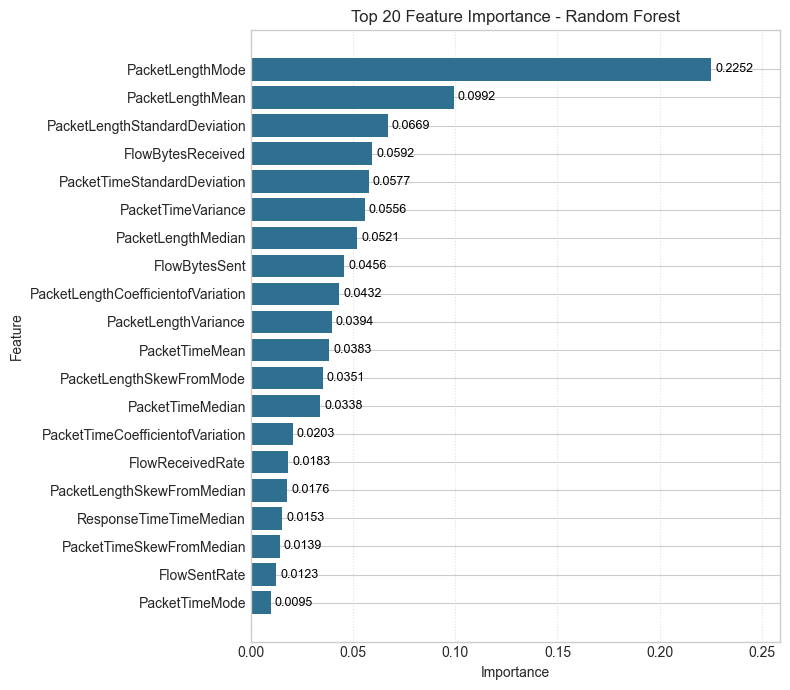

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\random_forest_feature_importance.png


In [14]:
rf_model = trained_models["Random Forest"]
rf_classifier = rf_model.named_steps["classifier"]

feature_importance_df = pd.DataFrame({
    "feature": numeric_features,
    "importance": rf_classifier.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(feature_importance_df)

top_features = feature_importance_df.head(20).sort_values("importance")
plt.figure(figsize=(8, 7))

bars = plt.barh(top_features["feature"], top_features["importance"], color="#2f6f8f")

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.002, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
             va='center', ha='left', fontsize=9, color='black')

plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.xlim(0, max(top_features["importance"]) * 1.15)

plt.tight_layout()
feature_importance_path = OUTPUT_DIR / "random_forest_feature_importance.png"
plt.savefig(feature_importance_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {feature_importance_path.resolve()}")

## C. Threshold dan Evaluasi Lanjutan

Blok ini memuat analisis threshold, metrik evaluasi lanjutan, validasi stabilitas, trial tuning ringan, dan profiling resource.

## 13. Threshold Analysis

,threshold,accuracy,precision,recall_tpr,f1_score,fpr,tn,fp,fn,tp
0,0.05,0.997409,0.994976,0.999940,0.997452,0.005197,48239,252,3,49905
1,0.10,0.998994,0.998080,0.999940,0.999009,0.001980,48395,96,3,49905
2,0.15,0.999370,0.998819,0.999940,0.999379,0.001217,48432,59,3,49905
3,0.20,0.999543,0.999159,0.999940,0.999549,0.000866,48449,42,3,49905
4,0.25,0.999705,0.999479,0.999940,0.999710,0.000536,48465,26,3,49905
5,0.30,0.999766,0.999619,0.999920,0.999770,0.000392,48472,19,4,49904
6,0.35,0.999776,0.999679,0.999880,0.999780,0.000330,48475,16,6,49902
7,0.40,0.999797,0.999740,0.999860,0.999800,0.000268,48478,13,7,49901
8,0.45,0.999888,0.999960,0.999820,0.999890,0.000041,48489,2,9,49899
9,0.50,0.999868,0.999960,0.999780,0.999870,0.000041,48489,2,11,49897


Best model berdasarkan ROC-AUC/F1/Recall: Random Forest
Threshold terpilih berdasarkan F1/Recall/Precision: 0.45


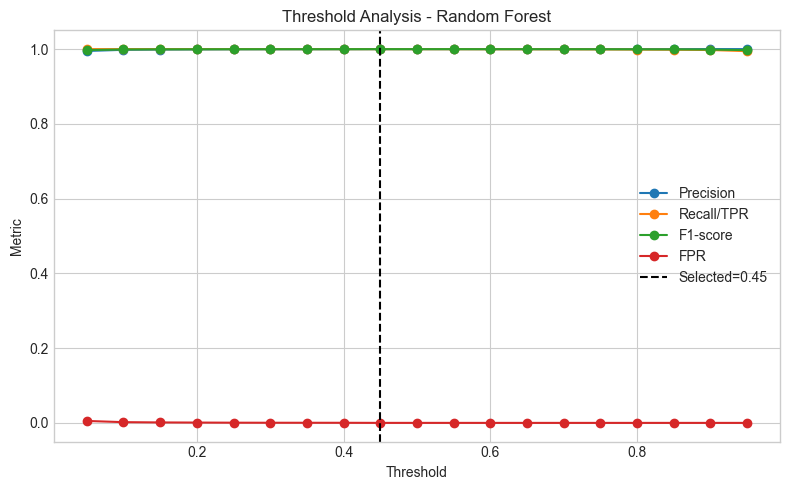

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\threshold_analysis.png


In [15]:
best_model_name = metrics_df.iloc[0]["model"]
best_record = next(record for record in evaluation_records if record["model"] == best_model_name)
best_model = trained_models[best_model_name]

threshold_rows = []
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    y_pred_threshold = (best_record["y_score"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, y_pred_threshold),
        "precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "recall_tpr": recall_score(y_test, y_pred_threshold, zero_division=0),
        "f1_score": f1_score(y_test, y_pred_threshold, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

threshold_df = pd.DataFrame(threshold_rows)
selected_threshold_row = threshold_df.sort_values(
    by=["f1_score", "fpr", "recall_tpr", "precision"],
    ascending=[False, True, False, False]
).iloc[0]
selected_threshold = float(selected_threshold_row["threshold"])

display(threshold_df)
print(f"Best model berdasarkan ROC-AUC/F1/Recall: {best_model_name}")
print(f"Threshold terpilih berdasarkan F1/Recall/Precision: {selected_threshold:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall_tpr"], marker="o", label="Recall/TPR")
plt.plot(threshold_df["threshold"], threshold_df["f1_score"], marker="o", label="F1-score")
plt.plot(threshold_df["threshold"], threshold_df["fpr"], marker="o", label="FPR")
plt.axvline(selected_threshold, linestyle="--", color="black", label=f"Selected={selected_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.title(f"Threshold Analysis - {best_model_name}")
plt.legend()
plt.tight_layout()
threshold_path = OUTPUT_DIR / "threshold_analysis.png"
plt.savefig(threshold_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {threshold_path.resolve()}")

## 14. Enhanced Threshold Analysis

,threshold,precision,recall_tpr,f1_score,specificity_tnr,fpr,alert_volume,alert_rate,utility_score,tn,fp,fn,tp
0,0.01,0.965226,1.000000,0.982306,0.962921,0.037079,51706,0.525473,2.853989,46693,1798,0,49908
1,0.02,0.983912,0.999960,0.991871,0.983172,0.016828,50722,0.515473,2.933349,47675,816,2,49906
2,0.03,0.989904,0.999940,0.994896,0.989503,0.010497,50414,0.512343,2.958293,47982,509,3,49905
3,0.04,0.992996,0.999940,0.996456,0.992741,0.007259,50257,0.510747,2.971099,48139,352,3,49905
4,0.05,0.994976,0.999940,0.997452,0.994803,0.005197,50157,0.509731,2.979265,48239,252,3,49905
...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,0.95,1.000000,0.994550,0.997268,1.000000,0.000000,49636,0.504436,2.989100,48491,0,272,49636
95,0.96,1.000000,0.993027,0.996501,1.000000,0.000000,49560,0.503664,2.986054,48491,0,348,49560
96,0.97,1.000000,0.990703,0.995330,1.000000,0.000000,49444,0.502485,2.981406,48491,0,464,49444
97,0.98,1.000000,0.986455,0.993181,1.000000,0.000000,49232,0.500330,2.972910,48491,0,676,49232


Enhanced threshold terpilih: 0.45


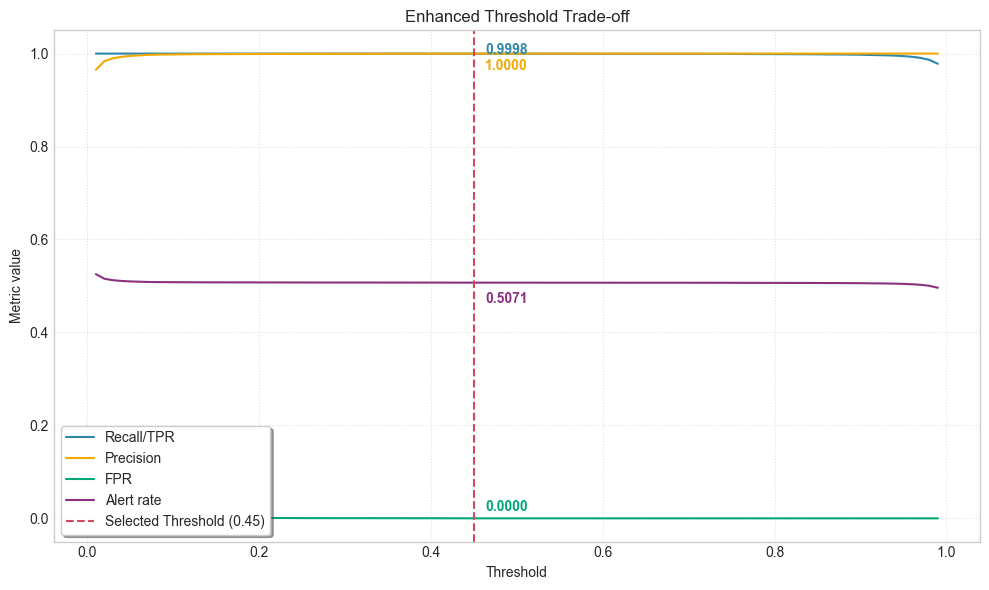

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_threshold_analysis.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_threshold_analysis.png


In [16]:
enhanced_threshold_rows = []
for threshold in np.round(np.arange(0.01, 1.00, 0.01), 2):
    y_pred_threshold = (best_record["y_score"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    fpr_value = fp / (fp + tn) if (fp + tn) else 0.0
    alert_volume = int(tp + fp)
    utility_score = (2.0 * recall) + precision - (3.0 * fpr_value)

    enhanced_threshold_rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall_tpr": recall,
        "f1_score": f1_score(y_test, y_pred_threshold, zero_division=0),
        "specificity_tnr": tn / (tn + fp) if (tn + fp) else 0.0,
        "fpr": fpr_value,
        "alert_volume": alert_volume,
        "alert_rate": alert_volume / len(y_test),
        "utility_score": utility_score,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

enhanced_threshold_df = pd.DataFrame(enhanced_threshold_rows)
enhanced_selected_threshold_row = enhanced_threshold_df.sort_values(
    by=["utility_score", "f1_score", "recall_tpr"],
    ascending=False,
).iloc[0]
enhanced_selected_threshold = float(enhanced_selected_threshold_row["threshold"])

display(enhanced_threshold_df)
print(f"Enhanced threshold terpilih: {enhanced_selected_threshold:.2f}")

plt.figure(figsize=(10, 6))

plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["recall_tpr"], label="Recall/TPR", color="#2E86AB")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["precision"], label="Precision", color="#F2A900")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["fpr"], label="FPR", color="#00A878")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["alert_rate"], label="Alert rate", color="#8A307F")

# Garis vertikal untuk threshold terpilih
plt.axvline(enhanced_selected_threshold, color="#D1495B", linestyle="--", 
            label=f"Selected Threshold ({enhanced_selected_threshold:.2f})")

sel_recall = enhanced_selected_threshold_row["recall_tpr"]
sel_precision = enhanced_selected_threshold_row["precision"]
sel_fpr = enhanced_selected_threshold_row["fpr"]
sel_alert = enhanced_selected_threshold_row["alert_rate"]

plt.annotate(f"{sel_recall:.4f}", xy=(enhanced_selected_threshold, sel_recall), 
             xytext=(8, 0), textcoords="offset points", color="#2E86AB", fontweight="bold")
plt.annotate(f"{sel_precision:.4f}", xy=(enhanced_selected_threshold, sel_precision), 
             xytext=(8, -12), textcoords="offset points", color="#F2A900", fontweight="bold")
plt.annotate(f"{sel_fpr:.4f}", xy=(enhanced_selected_threshold, sel_fpr), 
             xytext=(8, 5), textcoords="offset points", color="#00A878", fontweight="bold")
plt.annotate(f"{sel_alert:.4f}", xy=(enhanced_selected_threshold, sel_alert), 
             xytext=(8, -15), textcoords="offset points", color="#8A307F", fontweight="bold")

plt.title("Enhanced Threshold Trade-off")
plt.xlabel("Threshold")
plt.ylabel("Metric value")

plt.legend(loc="best", frameon=True, shadow=True)
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

enhanced_threshold_path = OUTPUT_DIR / "enhanced_threshold_analysis.csv"
enhanced_threshold_plot_path = OUTPUT_DIR / "enhanced_threshold_analysis.png"
enhanced_threshold_df.to_csv(enhanced_threshold_path, index=False)
plt.savefig(enhanced_threshold_plot_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Saved: {enhanced_threshold_path.resolve()}")
print(f"Saved: {enhanced_threshold_plot_path.resolve()}")

## 15. Advanced Evaluation Metrics

In [17]:
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
)

advanced_metric_rows = []
for record in evaluation_records:
    y_score = record["y_score"]
    y_pred = (y_score >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else 0.0
    fdr = fp / (fp + tp) if (fp + tp) else 0.0

    advanced_metric_rows.append({
        "model": record["model"],
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "average_precision": average_precision_score(y_test, y_score),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "specificity_tnr": specificity,
        "negative_predictive_value": npv,
        "false_discovery_rate": fdr,
        "false_positive_rate": record["fpr"],
        "false_negative_count": int(fn),
        "false_positive_count": int(fp),
    })

advanced_metrics_df = pd.DataFrame(advanced_metric_rows).sort_values(
    by=["average_precision", "mcc", "balanced_accuracy"],
    ascending=False,
).reset_index(drop=True)

display(advanced_metrics_df)

advanced_metrics_path = OUTPUT_DIR / "advanced_evaluation_metrics.csv"
advanced_metrics_df.to_csv(advanced_metrics_path, index=False)
print(f"Saved: {advanced_metrics_path.resolve()}")

,model,balanced_accuracy,average_precision,mcc,specificity_tnr,negative_predictive_value,false_discovery_rate,false_positive_rate,false_negative_count,false_positive_count
0,Random Forest,0.999869,0.999999,0.999736,0.999959,0.999773,0.000040,0.000041,11,2
1,AdaBoost,0.998266,0.999961,0.996524,0.998556,0.997918,0.001403,0.001444,101,70
2,Logistic Regression,0.900762,0.953172,0.805058,0.859190,0.935385,0.126778,0.140810,2878,6828


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\advanced_evaluation_metrics.csv


## 16. Cross-Validation / Stability Check

In [18]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "balanced_accuracy": "balanced_accuracy",
}

cv_result = cross_validate(
    clone(best_model),
    X,
    y,
    cv=cv,
    scoring=cv_scoring,
    n_jobs=-1,
    return_train_score=False,
)

cv_summary_rows = []
for metric_name in cv_scoring:
    values = cv_result[f"test_{metric_name}"]
    cv_summary_rows.append({
        "metric": metric_name,
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "min": float(np.min(values)),
        "max": float(np.max(values)),
    })

cv_summary_df = pd.DataFrame(cv_summary_rows)
display(cv_summary_df)

cv_summary_path = OUTPUT_DIR / "cross_validation_stability.csv"
cv_summary_df.to_csv(cv_summary_path, index=False)
print(f"Saved: {cv_summary_path.resolve()}")

,metric,mean,std,min,max
0,roc_auc,1.000000,1.052734e-07,1.000000,1.00000
1,f1,0.999876,2.876006e-05,0.999840,0.99992
2,recall,0.999824,5.435834e-05,0.999740,0.99990
3,precision,0.999928,5.610171e-05,0.999860,0.99998
4,balanced_accuracy,0.999875,2.921107e-05,0.999838,0.99992


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\cross_validation_stability.csv


## 17. Lightweight GridSearchCV Trial

In [20]:
from sklearn.model_selection import GridSearchCV

lightweight_rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    )),
])

lightweight_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 12],
    "classifier__min_samples_leaf": [1, 3],
}

grid_search = GridSearchCV(
    lightweight_rf_pipeline,
    param_grid=lightweight_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

grid_results_df = pd.DataFrame(grid_search.cv_results_).sort_values(
    "rank_test_score"
)[[
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "param_classifier__n_estimators",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
]]

lightweight_grid_best_model = grid_search.best_estimator_
lightweight_grid_scores = get_positive_scores(lightweight_grid_best_model, X_test)
lightweight_grid_pred = (lightweight_grid_scores >= 0.5).astype(int)
lightweight_grid_summary = {
    "best_params": grid_search.best_params_,
    "cv_best_roc_auc": float(grid_search.best_score_),
    "test_roc_auc": roc_auc_score(y_test, lightweight_grid_scores),
    "test_f1_default_threshold": f1_score(y_test, lightweight_grid_pred, zero_division=0),
    "test_recall_default_threshold": recall_score(y_test, lightweight_grid_pred, zero_division=0),
    "test_precision_default_threshold": precision_score(y_test, lightweight_grid_pred, zero_division=0),
}

display(grid_results_df)
display(pd.DataFrame([lightweight_grid_summary]))

grid_results_path = OUTPUT_DIR / "lightweight_gridsearch_results.csv"
grid_summary_path = OUTPUT_DIR / "lightweight_gridsearch_summary.json"
grid_results_df.to_csv(grid_results_path, index=False)
with grid_summary_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(lightweight_grid_summary), file, indent=2)
print(f"Saved: {grid_results_path.resolve()}")
print(f"Saved: {grid_summary_path.resolve()}")

,rank_test_score,mean_test_score,std_test_score,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_leaf
1,1,1.000000,3.238693e-08,200,None,1
0,2,1.000000,3.337139e-08,100,None,1
3,3,1.000000,4.465144e-08,200,None,3
2,4,1.000000,5.296995e-08,100,None,3
5,5,0.999999,4.081888e-08,200,12,1
4,6,0.999999,3.947246e-08,100,12,1
6,7,0.999999,1.448123e-07,100,12,3
7,8,0.999999,1.756975e-07,200,12,3


,best_params,cv_best_roc_auc,test_roc_auc,test_f1_default_threshold,test_recall_default_threshold,test_precision_default_threshold
0,"{'classifier__max_depth': None, 'classifier__m...",1.0,0.999999,0.99987,0.99978,0.99996


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\lightweight_gridsearch_results.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\lightweight_gridsearch_summary.json


## 18. Resource Profiling

In [23]:
import gc
import tracemalloc

gc.collect()
tracemalloc.start()
profile_start = time.perf_counter()
profile_scores = get_positive_scores(best_model, X_test)
profile_predictions = (profile_scores >= selected_threshold).astype(int)
profile_elapsed_sec = time.perf_counter() - profile_start
current_memory, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

resource_profile = {
    "model": best_model_name,
    "rows_profiled": int(len(X_test)),
    "threshold": selected_threshold,
    "inference_time_sec": profile_elapsed_sec,
    "throughput_rows_per_sec": len(X_test) / profile_elapsed_sec if profile_elapsed_sec > 0 else np.inf,
    "peak_memory_mb": peak_memory / (1024 ** 2),
    "predicted_alerts": int(profile_predictions.sum()),
}
resource_profile_df = pd.DataFrame([resource_profile])
display(resource_profile_df)

resource_profile_path = OUTPUT_DIR / "resource_profile_simple.csv"
resource_profile_df.to_csv(resource_profile_path, index=False)
print(f"Saved: {resource_profile_path.resolve()}")

,model,rows_profiled,threshold,inference_time_sec,throughput_rows_per_sec,peak_memory_mb,predicted_alerts
0,Random Forest,98399,0.45,0.344658,285497.507685,50.523001,49901


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\resource_profile_simple.csv


## D. Explainability dan Robustness Analysis

Blok ini memuat explainability, error analysis, distribusi probabilitas prediksi, borderline sample analysis, Top-N feature experiment, dan ablation study sederhana.

## 19. Explainability Trial: SHAP Optional / Permutation Importance

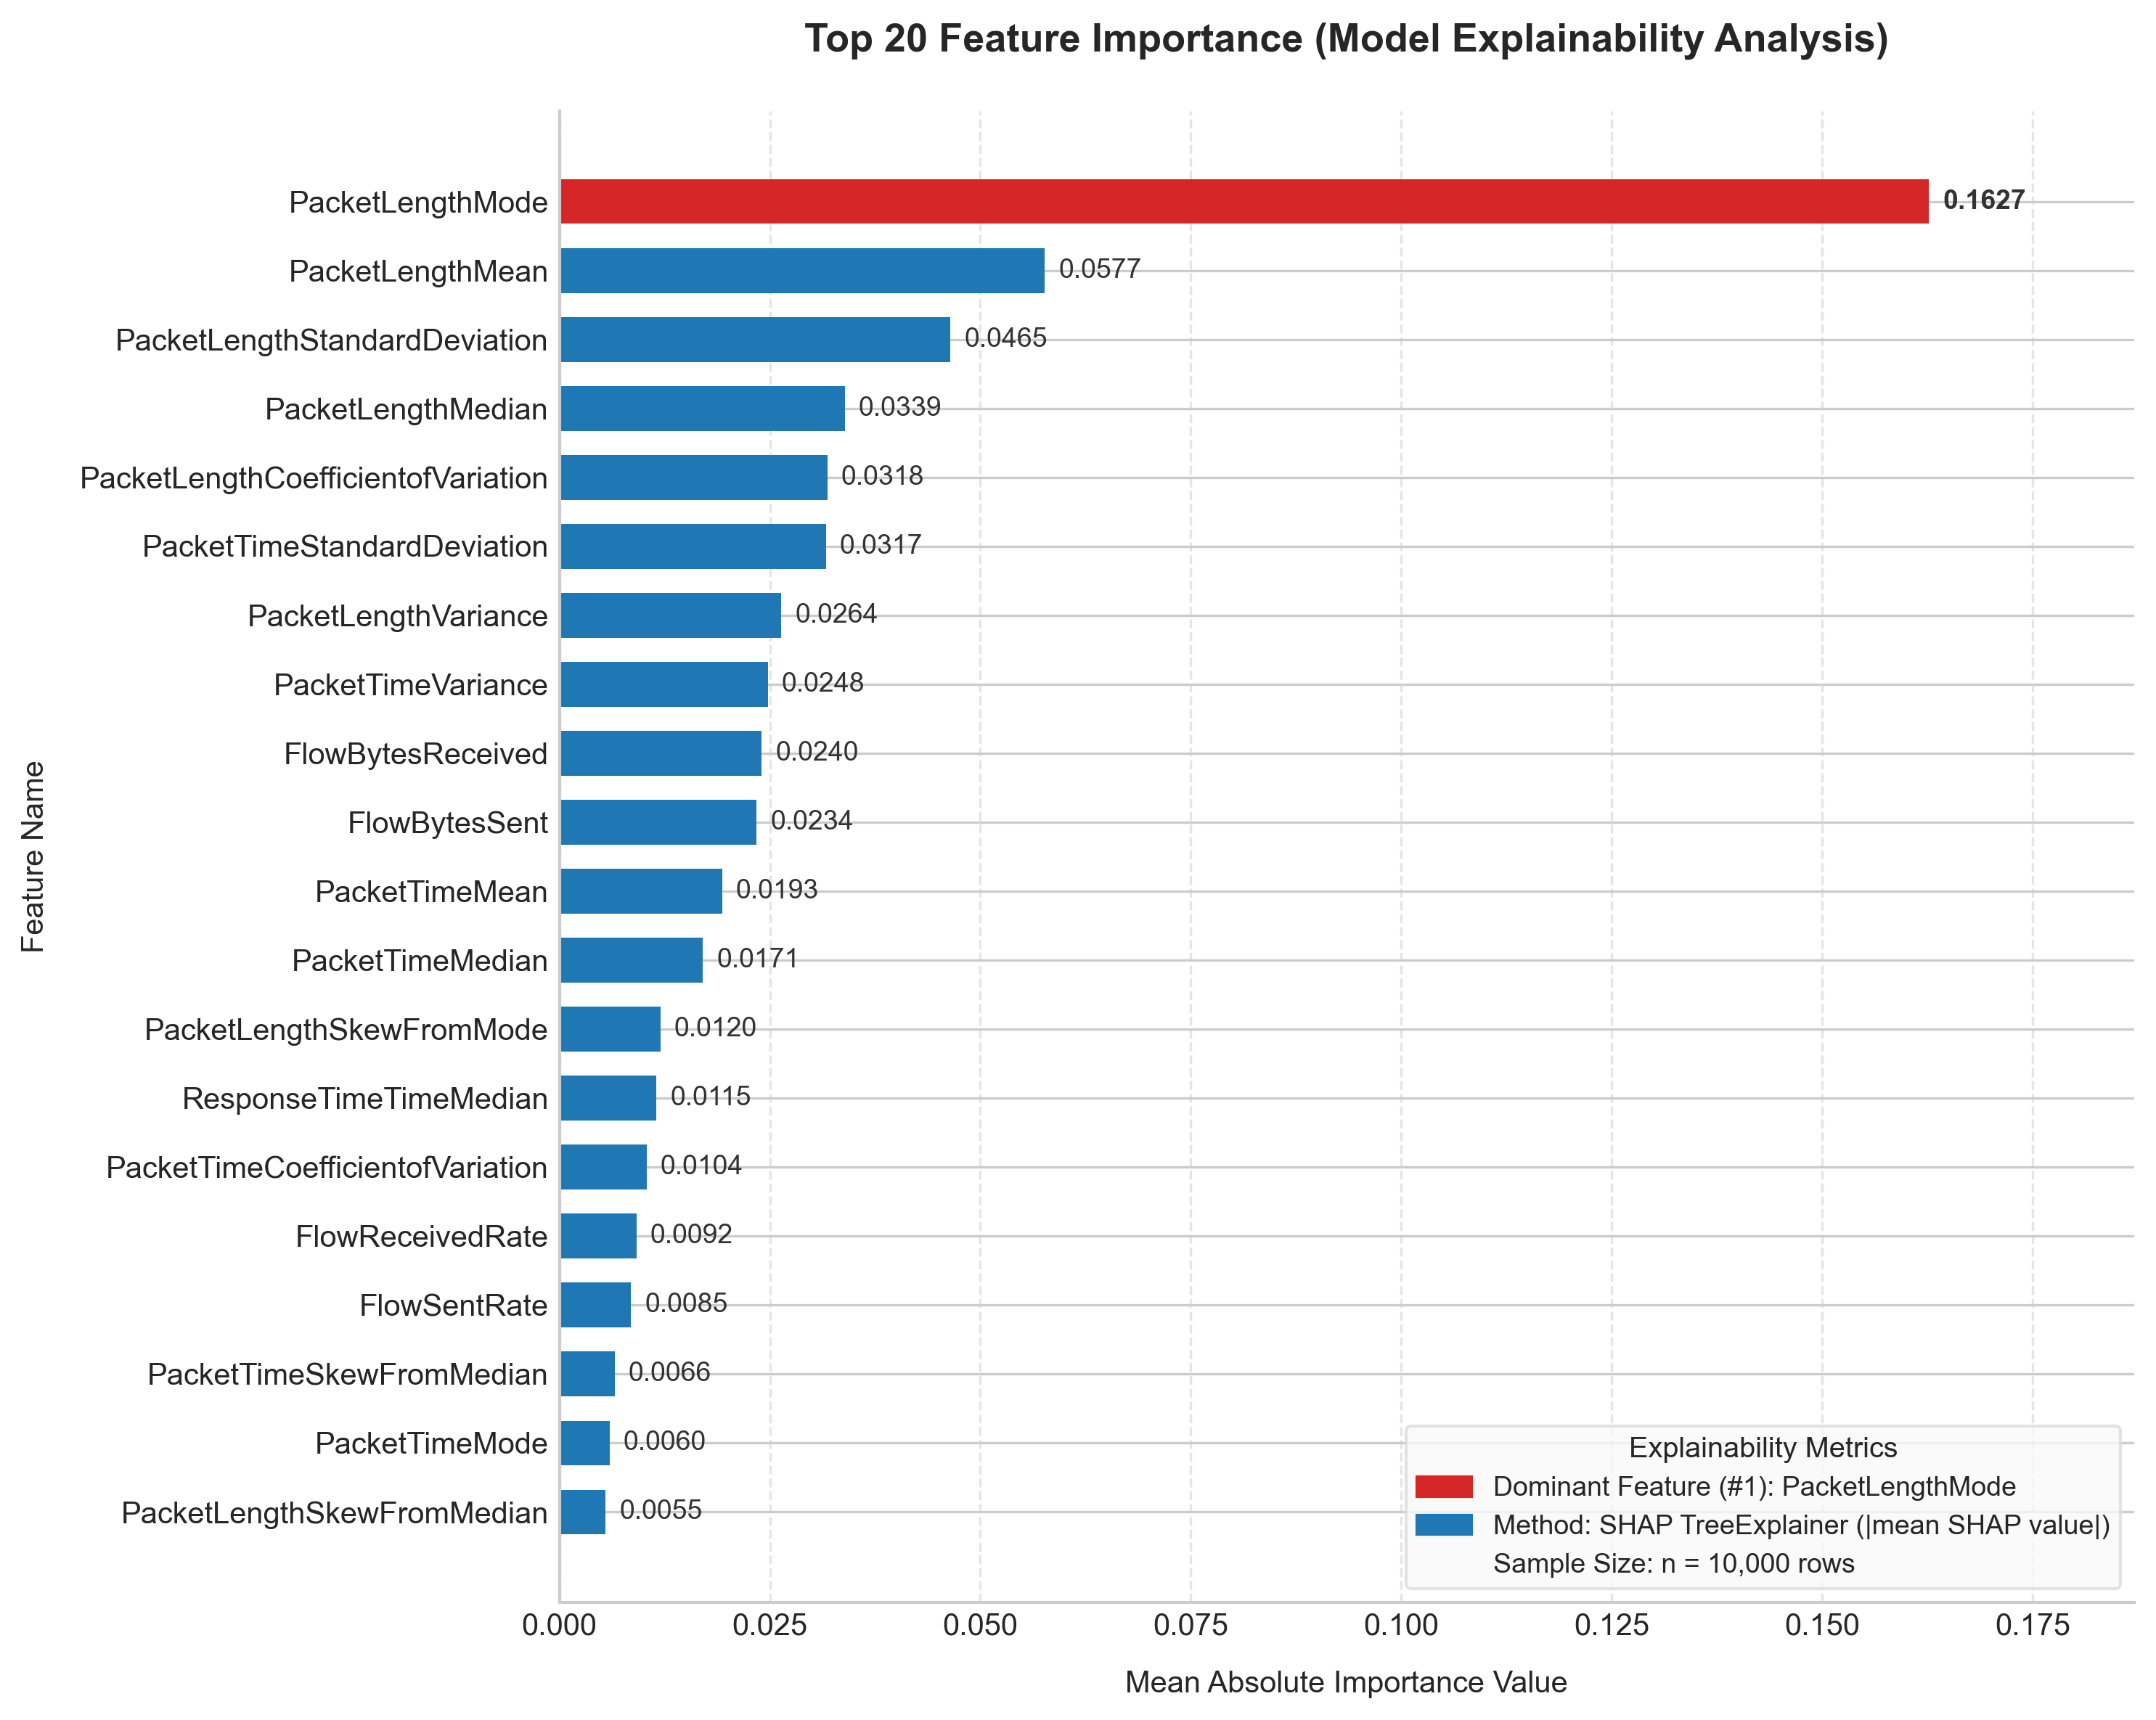

Saved PNG (Pro with Legend): D:\Skripsi\doh_exfiltration_skripsi\outputs\explainability_importance.png


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# 1. Stratified Sampling (10.000 sampel agar representatif sesuai Revisi R8)
explainability_sample_size = min(10000, len(X_test))

_, X_explain, _, y_explain = train_test_split(
    X_test, 
    y_test, 
    test_size=explainability_sample_size, 
    stratify=y_test, 
    random_state=RANDOM_STATE
)

try:
    import shap

    # 2. Transformasi via Imputer & Kembalikan ke DataFrame berkolom
    transformed_array = best_model.named_steps["imputer"].transform(X_explain)
    transformed_explain = pd.DataFrame(transformed_array, columns=numeric_features, index=X_explain.index)
    
    # 3. Hitung SHAP Values
    classifier = best_model.named_steps["classifier"]
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(transformed_explain)
    
    # 4. Handle Format SHAP untuk Kelas Positif (Malicious / Label 1)
    if isinstance(shap_values, list):
        shap_array = shap_values[1]
    elif hasattr(shap_values, "values") and len(shap_values.values.shape) == 3:
        shap_array = shap_values.values[:, :, 1]
    elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
        shap_array = shap_values[:, :, 1]
    else:
        shap_array = shap_values

    # Hitung Mean Absolute SHAP Importance
    mean_shap = np.abs(shap_array).mean(axis=0)
    
    explainability_df = pd.DataFrame({
        "feature": numeric_features,
        "mean_abs_importance": mean_shap,
        "method": "shap_tree_explainer",
    }).sort_values("mean_abs_importance", ascending=False).reset_index(drop=True)

    # Generate SHAP Beeswarm Summary Plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_array, transformed_explain, max_display=20, show=False)
    plt.title("SHAP Summary Plot (Top 20 Features)", fontsize=12, fontweight="bold", pad=15)
    shap_summary_path = OUTPUT_DIR / "shap_summary_beeswarm.png"
    plt.savefig(shap_summary_path, dpi=300, bbox_inches="tight")
    plt.close()

except Exception as shap_error:
    print(f"SHAP gagal atau tidak digunakan: {shap_error}")
    
    permutation_result = permutation_importance(
        best_model,
        X_explain,
        y_explain,
        n_repeats=5,
        random_state=RANDOM_STATE,
        scoring="roc_auc",
        n_jobs=-1,
    )
    explainability_df = pd.DataFrame({
        "feature": numeric_features,
        "mean_abs_importance": permutation_result.importances_mean,
        "importance_std": permutation_result.importances_std,
        "method": "permutation_importance",
    }).sort_values("mean_abs_importance", ascending=False).reset_index(drop=True)

# ---------------------------------------------------------
# VISUALISASI PRO BAR CHART DENGAN LEGEND & VALUE LABELS
# ---------------------------------------------------------
plot_data = explainability_df.head(20).sort_values("mean_abs_importance")

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

# Warna gradien profesional: Fitur Paling Dominan (Merah/Navy) vs Fitur Pendukung
method_used = plot_data["method"].iloc[0]
if "shap" in method_used:
    base_color = "#1f77b4"      # Soft Navy Blue
    top_color = "#d62728"       # Crimson Red (untuk memunculkan highlight fitur #1)
    method_label = "SHAP TreeExplainer (|mean SHAP value|)"
else:
    base_color = "#2ca02c"      # Green
    top_color = "#ff7f0e"       # Orange
    method_label = "Permutation Importance (Mean ROC-AUC Drop)"

# Beri warna beda khusus untuk fitur teratas (#1)
colors = [top_color if i == len(plot_data) - 1 else base_color for i in range(len(plot_data))]

bars = ax.barh(plot_data["feature"], plot_data["mean_abs_importance"], color=colors, edgecolor="none", height=0.65)

# 1. Tambahkan Angka Nilai Importance di Ujung Setiap Bar
max_val = plot_data["mean_abs_importance"].max()
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (max_val * 0.01), 
        bar.get_y() + bar.get_height() / 2, 
        f"{width:.4f}", 
        va="center", 
        ha="left", 
        fontsize=9, 
        color="#333333",
        fontweight="bold" if width == max_val else "normal"
    )

# 2. Desain Layout & Gridline Halus
ax.set_xlim(0, max_val * 1.15)  # Memberi ruang untuk teks di kanan
ax.set_title("Top 20 Feature Importance (Model Explainability Analysis)", fontsize=13, fontweight="bold", pad=20)
ax.set_xlabel("Mean Absolute Importance Value", fontsize=10, labelpad=10)
ax.set_ylabel("Feature Name", fontsize=10, labelpad=10)
ax.xaxis.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
ax.set_axisbelow(True)

# Trim Spine/Border Tepi
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# 3. KUSTOMISASI LEGEND PRO
legend_top = mpatches.Patch(color=top_color, label=f"Dominant Feature (#1): {plot_data['feature'].iloc[-1]}")
legend_other = mpatches.Patch(color=base_color, label=f"Method: {method_label}")
legend_sample = mpatches.Patch(color="none", label=f"Sample Size: n = {len(X_explain):,} rows")

ax.legend(
    handles=[legend_top, legend_other, legend_sample],
    loc="lower right",
    frameon=True,
    facecolor="#f9f9f9",
    edgecolor="#dddddd",
    fontsize=9,
    title="Explainability Metrics",
    title_fontsize=9.5
)

plt.tight_layout()

# Simpan Gambar
explainability_path = OUTPUT_DIR / "explainability_importance.csv"
explainability_plot_path = OUTPUT_DIR / "explainability_importance.png"

explainability_df.to_csv(explainability_path, index=False)
plt.savefig(explainability_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved PNG (Pro with Legend): {explainability_plot_path.resolve()}")

## 20. Error Analysis: False Positive dan False Negative

In [27]:

try:
    import time, json, warnings
    from pathlib import Path
    import numpy as np
    import pandas as pd
    warnings.filterwarnings('ignore')

    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs'))
    output_dir.mkdir(parents=True, exist_ok=True)
    globals()['OUTPUT_DIR'] = output_dir

    def _to_frame(data, prefix='feature'):
        if data is None:
            return pd.DataFrame()
        if isinstance(data, pd.DataFrame):
            return data.copy()
        arr = np.asarray(data)
        if arr.ndim == 1:
            arr = arr.reshape(-1, 1)
        cols = list(globals().get('numeric_features', []))
        if cols and arr.ndim == 2 and len(cols) == arr.shape[1]:
            return pd.DataFrame(arr, columns=cols)
        return pd.DataFrame(arr, columns=[f'{prefix}_{i}' for i in range(arr.shape[1])])

    def _to_series(data, name='target'):
        if data is None:
            return pd.Series(dtype='float64', name=name)
        return pd.Series(np.ravel(np.asarray(data)), name=name)

    def _positive_label(model, y_values):
        classes = getattr(model, 'classes_', None)
        if classes is not None and len(classes) > 1:
            return classes[-1]
        vals = pd.Series(y_values).dropna().unique().tolist()
        return sorted(vals)[-1] if len(vals) > 1 else 1

    def _prediction_context():
        model = globals().get('best_model', None)
        model_name = globals().get('best_model_name', type(model).__name__ if model is not None else 'unavailable')
        threshold = globals().get('enhanced_selected_threshold', globals().get('selected_threshold', 0.5))
        try:
            threshold = float(threshold)
        except Exception:
            threshold = 0.5
        X_eval = _to_frame(globals().get('X_test', None))
        y_true = _to_series(globals().get('y_test', None), 'y_true')
        if len(X_eval) and len(y_true):
            n = min(len(X_eval), len(y_true))
            X_eval, y_true = X_eval.iloc[:n].reset_index(drop=True), y_true.iloc[:n].reset_index(drop=True)
        positive_label = _positive_label(model, y_true) if model is not None else 1
        probs, labels, status = np.array([], dtype=float), np.array([], dtype=object), 'ok'
        if model is None or X_eval.empty or y_true.empty:
            status = 'missing_model_or_test_data'
        else:
            try:
                if hasattr(model, 'predict_proba'):
                    pred_proba = model.predict_proba(X_eval)
                    classes = list(getattr(model, 'classes_', []))
                    pos_idx = classes.index(positive_label) if positive_label in classes else pred_proba.shape[1] - 1
                    probs = pred_proba[:, pos_idx] if pred_proba.ndim == 2 else np.ravel(pred_proba)
                    labels = np.where(probs >= threshold, positive_label, 0)
                elif hasattr(model, 'decision_function'):
                    scores = np.ravel(model.decision_function(X_eval))
                    probs = 1.0 / (1.0 + np.exp(-scores))
                    labels = np.where(probs >= threshold, positive_label, 0)
                    status = 'used_decision_function_probability_proxy'
                else:
                    labels = np.ravel(model.predict(X_eval))
                    probs = np.full(len(labels), np.nan)
                    status = 'used_predict_without_probability'
            except Exception as pred_error:
                status = f'prediction_failed: {pred_error}'
        return {'model': model, 'model_name': model_name, 'threshold': threshold, 'X_eval': X_eval,
                'y_true': y_true, 'positive_label': positive_label, 'probability': pd.Series(probs),
                'y_pred': pd.Series(labels), 'status': status}

    robustness_context = _prediction_context()
    X_eval, y_true = robustness_context['X_eval'], robustness_context['y_true']
    y_pred, prob = robustness_context['y_pred'], robustness_context['probability']
    positive_label = robustness_context['positive_label']
    if len(X_eval) and len(y_true) and len(y_pred):
        n = min(len(X_eval), len(y_true), len(y_pred), len(prob) if len(prob) else len(y_pred))
        result_df = X_eval.iloc[:n].copy().reset_index(drop=True)
        result_df['y_true'] = y_true.iloc[:n].values
        result_df['y_pred'] = y_pred.iloc[:n].values
        result_df['pred_probability'] = prob.iloc[:n].values if len(prob) else np.nan
        result_df['error_type'] = 'correct'
        fp_mask = (result_df['y_true'] != positive_label) & (result_df['y_pred'] == positive_label)
        fn_mask = (result_df['y_true'] == positive_label) & (result_df['y_pred'] != positive_label)
        result_df.loc[fp_mask, 'error_type'] = 'false_positive'
        result_df.loc[fn_mask, 'error_type'] = 'false_negative'
        false_positive_samples = result_df.loc[fp_mask].copy()
        false_negative_samples = result_df.loc[fn_mask].copy()
    else:
        false_positive_samples = pd.DataFrame()
        false_negative_samples = pd.DataFrame()
    total = int(len(X_eval)) if len(X_eval) else 0
    fp_count, fn_count = len(false_positive_samples), len(false_negative_samples)
    error_summary = pd.DataFrame([{'model_name': robustness_context['model_name'], 'threshold': robustness_context['threshold'],
        'status': robustness_context['status'], 'total_samples': total, 'false_positive_count': fp_count,
        'false_negative_count': fn_count, 'false_positive_rate': fp_count / total if total else np.nan,
        'false_negative_rate': fn_count / total if total else np.nan, 'generated_at': time.strftime('%Y-%m-%d %H:%M:%S')}])
    error_summary.to_csv(output_dir / 'error_analysis_summary.csv', index=False)
    false_positive_samples.to_csv(output_dir / 'false_positive_samples.csv', index=False)
    false_negative_samples.to_csv(output_dir / 'false_negative_samples.csv', index=False)
    print('Error analysis saved:', output_dir / 'error_analysis_summary.csv')
    display(error_summary)
except Exception as e:
    from pathlib import Path
    import pandas as pd
    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs')); output_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([{'status': f'failed: {e}'}]).to_csv(output_dir / 'error_analysis_summary.csv', index=False)
    pd.DataFrame().to_csv(output_dir / 'false_positive_samples.csv', index=False)
    pd.DataFrame().to_csv(output_dir / 'false_negative_samples.csv', index=False)
    print('Section 24 failed safely:', e)


Error analysis saved: ..\outputs\error_analysis_summary.csv


,model_name,threshold,status,total_samples,false_positive_count,false_negative_count,false_positive_rate,false_negative_rate,generated_at
0,Random Forest,0.45,ok,98399,2,9,0.00002,0.000091,2026-08-06 15:28:34


## 21. Prediction Probability Distribution

In [28]:
try:
    import time
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    if "robustness_context" not in globals():
        robustness_context = _prediction_context()

    prob = robustness_context.get("probability", pd.Series(dtype=float)).dropna().astype(float)
    y_true = robustness_context.get("y_true", pd.Series(dtype=object))
    threshold = float(robustness_context.get("threshold", 0.5))

    rows = []

    if len(prob):
        rows.append({
            "scope": "overall",
            "count": int(prob.count()),
            "mean": float(prob.mean()),
            "std": float(prob.std(ddof=0)),
            "min": float(prob.min()),
            "q05": float(prob.quantile(0.05)),
            "q25": float(prob.quantile(0.25)),
            "median": float(prob.quantile(0.50)),
            "q75": float(prob.quantile(0.75)),
            "q95": float(prob.quantile(0.95)),
            "max": float(prob.max()),
            "threshold": threshold,
            "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        if len(y_true) == len(prob):
            temp = pd.DataFrame({
                "y_true": y_true.values,
                "pred_probability": prob.values
            })

            for label, group in temp.groupby("y_true"):
                rows.append({
                    "scope": f"y_true={label}",
                    "count": int(len(group)),
                    "mean": float(group["pred_probability"].mean()),
                    "std": float(group["pred_probability"].std(ddof=0)),
                    "min": float(group["pred_probability"].min()),
                    "q05": float(group["pred_probability"].quantile(0.05)),
                    "q25": float(group["pred_probability"].quantile(0.25)),
                    "median": float(group["pred_probability"].quantile(0.50)),
                    "q75": float(group["pred_probability"].quantile(0.75)),
                    "q95": float(group["pred_probability"].quantile(0.95)),
                    "max": float(group["pred_probability"].max()),
                    "threshold": threshold,
                    "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
                })

        plt.figure(figsize=(10, 6)) 
        
        # Simpan output histogram ke variabel untuk di-looping
        counts, bins, patches = plt.hist(prob, bins=30, color="#2E86AB", alpha=0.82, edgecolor="white")
        
        # Looping untuk mencetak angka di atas tiap batang
        for count, patch in zip(counts, patches):
            if count > 0:
                plt.text(
                    patch.get_x() + patch.get_width() / 2,
                    patch.get_height() + (max(counts) * 0.015),
                    f'{int(count)}',
                    ha='center', 
                    va='bottom', 
                    fontsize=8, 
                    color='black',
                    rotation=45 
                )

        plt.axvline(
            threshold,
            color="#D1495B",
            linestyle="--",
            linewidth=2,
            label=f"Threshold = {threshold:.3f}"
        )
        plt.title("Prediction Probability Distribution")
        plt.xlabel("Predicted probability")
        plt.ylabel("Sample count")

        plt.margins(y=0.15) 
        
        plt.legend()
        # -----------------------------------

    else:
        rows.append({
            "scope": "overall",
            "count": 0,
            "status": robustness_context.get("status", "probability_unavailable"),
            "threshold": threshold,
            "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        plt.figure(figsize=(9, 5))
        plt.text(0.5, 0.5, "Probability values unavailable", ha="center", va="center")
        plt.axis("off")

    probability_summary = pd.DataFrame(rows)
    probability_summary.to_csv(output_dir / "prediction_probability_summary.csv", index=False)

    plt.tight_layout()
    plt.savefig(output_dir / "prediction_probability_distribution.png", dpi=160)
    plt.close()

    print("Probability distribution outputs saved.")
    display(probability_summary)

except Exception as e:
    from pathlib import Path
    import pandas as pd
    import matplotlib.pyplot as plt

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    pd.DataFrame([{"status": f"failed: {e}"}]).to_csv(
        output_dir / "prediction_probability_summary.csv",
        index=False
    )

    plt.figure(figsize=(9, 5))
    plt.text(
        0.5,
        0.5,
        f"Section 25 failed safely:\n{e}",
        ha="center",
        va="center"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(output_dir / "prediction_probability_distribution.png", dpi=160)
    plt.close()

    print("Section 25 failed safely:", e)

Probability distribution outputs saved.


,scope,count,mean,std,min,q05,q25,median,q75,q95,max,threshold,generated_at
0,overall,98399,0.507107,0.498716,0.000,0.000,0.0,0.98,1.0,1.000,1.00,0.45,2026-08-06 15:28:39
1,y_true=0,48491,0.001367,0.011961,0.000,0.000,0.0,0.00,0.0,0.005,0.57,0.45,2026-08-06 15:28:39
2,y_true=1,49908,0.998488,0.016341,0.015,0.995,1.0,1.00,1.0,1.000,1.00,0.45,2026-08-06 15:28:39


## 22. Borderline Sample Analysis

In [29]:

try:
    import time
    from pathlib import Path
    import numpy as np
    import pandas as pd
    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs')); output_dir.mkdir(parents=True, exist_ok=True)
    if 'robustness_context' not in globals():
        robustness_context = _prediction_context()
    X_eval = robustness_context.get('X_eval', pd.DataFrame())
    y_true = robustness_context.get('y_true', pd.Series(dtype=object))
    y_pred = robustness_context.get('y_pred', pd.Series(dtype=object))
    prob = robustness_context.get('probability', pd.Series(dtype=float))
    threshold = float(robustness_context.get('threshold', 0.5))
    if len(X_eval) and len(prob):
        n = min(len(X_eval), len(y_true), len(y_pred), len(prob))
        borderline_df = X_eval.iloc[:n].copy().reset_index(drop=True)
        borderline_df['y_true'] = y_true.iloc[:n].values; borderline_df['y_pred'] = y_pred.iloc[:n].values
        borderline_df['pred_probability'] = prob.iloc[:n].values; borderline_df['threshold'] = threshold
        borderline_df['absolute_margin'] = (borderline_df['pred_probability'] - threshold).abs()
        borderline_df = borderline_df.sort_values('absolute_margin').reset_index(drop=True)
        selected_borderline = borderline_df.head(min(50, len(borderline_df))).copy()
        borderline_summary = pd.DataFrame([{'total_samples': int(len(borderline_df)), 'saved_borderline_samples': int(len(selected_borderline)),
            'within_0_05_margin': int((borderline_df.absolute_margin <= .05).sum()), 'minimum_margin': float(borderline_df.absolute_margin.min()),
            'median_margin': float(borderline_df.absolute_margin.median()), 'threshold': threshold,
            'status': robustness_context.get('status', 'ok'), 'generated_at': time.strftime('%Y-%m-%d %H:%M:%S')}])
    else:
        selected_borderline = pd.DataFrame()
        borderline_summary = pd.DataFrame([{'total_samples': 0, 'saved_borderline_samples': 0, 'within_0_05_margin': 0,
            'threshold': threshold, 'status': robustness_context.get('status', 'probability_unavailable'), 'generated_at': time.strftime('%Y-%m-%d %H:%M:%S')}])
    selected_borderline.to_csv(output_dir / 'borderline_samples.csv', index=False)
    borderline_summary.to_csv(output_dir / 'borderline_summary.csv', index=False)
    print('Borderline analysis outputs saved.'); display(borderline_summary)
except Exception as e:
    from pathlib import Path
    import pandas as pd
    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs')); output_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame().to_csv(output_dir / 'borderline_samples.csv', index=False)
    pd.DataFrame([{'status': f'failed: {e}'}]).to_csv(output_dir / 'borderline_summary.csv', index=False)
    print('Section 26 failed safely:', e)


Borderline analysis outputs saved.


,total_samples,saved_borderline_samples,within_0_05_margin,minimum_margin,median_margin,threshold,status,generated_at
0,98399,50,15,0.005,0.53,0.45,ok,2026-08-06 15:28:46


## 23. Top-N Feature Experiment


In [30]:

try:
    import time
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    from sklearn.feature_selection import mutual_info_classif
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (
        accuracy_score,
        f1_score,
        precision_score,
        recall_score,
        roc_auc_score,
    )
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    X_train_df = _to_frame(globals().get("X_train", None))
    X_test_df = _to_frame(globals().get("X_test", None))
    y_train_s = _to_series(globals().get("y_train", None), "y_train")
    y_test_s = _to_series(globals().get("y_test", None), "y_test")

    common_cols = [c for c in X_train_df.columns if c in set(X_test_df.columns)]

    numeric_cols = [
        c for c in list(globals().get("numeric_features", []))
        if c in common_cols
    ]

    if not numeric_cols and common_cols:
        numeric_cols = (
            X_train_df[common_cols]
            .select_dtypes(include=[np.number])
            .columns
            .tolist()
        )

    rows = []
    status = "Top-N experiment skipped because model data or numeric features were unavailable."

    if (
        len(X_train_df)
        and len(X_test_df)
        and len(y_train_s)
        and len(y_test_s)
        and numeric_cols
    ):
        n_train = min(len(X_train_df), len(y_train_s))
        n_test = min(len(X_test_df), len(y_test_s))

        Xtr = X_train_df.iloc[:n_train][numeric_cols]
        Xte = X_test_df.iloc[:n_test][numeric_cols]
        ytr = y_train_s.iloc[:n_train]
        yte = y_test_s.iloc[:n_test]

        imputer_for_ranking = SimpleImputer(strategy="median")
        Xtr_imputed = imputer_for_ranking.fit_transform(Xtr)

        mi_scores = mutual_info_classif(
            Xtr_imputed,
            ytr,
            random_state=42,
            discrete_features=False
        )

        ranked = (
            pd.Series(mi_scores, index=numeric_cols)
            .sort_values(ascending=False)
            .index
            .tolist()
        )

        top_n_candidates = sorted(
            set([n for n in [5, 10, 15, 20, 30, len(ranked)] if n <= len(ranked)])
        )

        for n_features in top_n_candidates:
            selected = ranked[:n_features]

            pipe = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                (
                    "model",
                    LogisticRegression(
                        max_iter=1000,
                        class_weight="balanced",
                        random_state=42
                    )
                ),
            ])

            start_train = time.perf_counter()
            pipe.fit(Xtr[selected], ytr)
            training_time_sec = time.perf_counter() - start_train

            start_infer = time.perf_counter()
            pred = pipe.predict(Xte[selected])
            prob = pipe.predict_proba(Xte[selected])[:, -1]
            inference_time_sec = time.perf_counter() - start_infer

            try:
                auc = roc_auc_score(yte, prob) if len(pd.Series(yte).unique()) > 1 else np.nan
            except Exception:
                auc = np.nan

            rows.append({
                "top_n": int(n_features),
                "feature_count": len(selected),
                "features": ", ".join(map(str, selected)),
                "accuracy": accuracy_score(yte, pred),
                "precision": precision_score(yte, pred, zero_division=0),
                "recall": recall_score(yte, pred, zero_division=0),
                "f1": f1_score(yte, pred, zero_division=0),
                "roc_auc": auc,
                "training_time_sec": training_time_sec,
                "inference_time_sec": inference_time_sec,
                "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
            })

        status = "Top-N experiment completed successfully."

    topn_results = pd.DataFrame(rows) if rows else pd.DataFrame([{"status": status}])

    topn_results.to_csv(
        output_dir / "top_n_feature_experiment.csv",
        index=False
    )

    (output_dir / "top_n_feature_experiment_status.txt").write_text(
        status,
        encoding="utf-8"
    )

    plt.figure(figsize=(9, 5))

    if "f1" in topn_results.columns:
        plt.plot(topn_results["top_n"], topn_results["f1"], marker="o", label="F1")
        plt.plot(topn_results["top_n"], topn_results["roc_auc"], marker="s", label="ROC-AUC")
        plt.xlabel("Top-N features")
        plt.ylabel("Score")
        plt.title("Top-N Feature Experiment")
        plt.ylim(0, 1.05)
        plt.legend()
    else:
        plt.text(0.5, 0.5, status, ha="center", va="center")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(output_dir / "top_n_feature_experiment.png", dpi=160)
    plt.close()

    print(status)
    display(topn_results)

except Exception as e:
    from pathlib import Path

    import matplotlib.pyplot as plt
    import pandas as pd

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    pd.DataFrame([{"status": f"failed: {e}"}]).to_csv(
        output_dir / "top_n_feature_experiment.csv",
        index=False
    )

    (output_dir / "top_n_feature_experiment_status.txt").write_text(
        f"failed: {e}",
        encoding="utf-8"
    )

    plt.figure(figsize=(9, 5))
    plt.text(
        0.5,
        0.5,
        f"Section 28 failed safely:\n{e}",
        ha="center",
        va="center"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(output_dir / "top_n_feature_experiment.png", dpi=160)
    plt.close()

    print("Section 28 failed safely:", e)

Top-N experiment completed successfully.


,top_n,feature_count,features,accuracy,precision,recall,f1,roc_auc,training_time_sec,inference_time_sec,generated_at
0,5,5,"PacketLengthMode, PacketLengthMedian, FlowByte...",0.511855,0.533912,0.295744,0.380643,0.619140,0.572420,0.043025,2026-08-06 15:29:53
1,10,10,"PacketLengthMode, PacketLengthMedian, FlowByte...",0.837244,0.847770,0.827743,0.837637,0.895803,1.962933,0.061111,2026-08-06 15:29:55
2,15,15,"PacketLengthMode, PacketLengthMedian, FlowByte...",0.894105,0.860700,0.943997,0.900426,0.946770,2.534872,0.081878,2026-08-06 15:29:58
3,20,20,"PacketLengthMode, PacketLengthMedian, FlowByte...",0.896208,0.865805,0.941252,0.901954,0.951745,3.695951,0.101959,2026-08-06 15:30:02
4,28,28,"PacketLengthMode, PacketLengthMedian, FlowByte...",0.901361,0.873222,0.942334,0.906463,0.958280,5.510646,0.143304,2026-08-06 15:30:07


## 24. Ablation Study Sederhana

Ablation sederhana ini menguji dampak penghapusan kelompok fitur berbasis nama fitur terhadap model pembanding ringan.

In [31]:
try:
    import time
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (
        accuracy_score,
        f1_score,
        precision_score,
        recall_score,
        roc_auc_score,
    )
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    X_train_df = _to_frame(globals().get("X_train", None))
    X_test_df = _to_frame(globals().get("X_test", None))
    y_train_s = _to_series(globals().get("y_train", None), "y_train")
    y_test_s = _to_series(globals().get("y_test", None), "y_test")

    common_cols = [c for c in X_train_df.columns if c in set(X_test_df.columns)]

    feature_cols = [
        c for c in list(globals().get("numeric_features", []))
        if c in common_cols
    ]

    if not feature_cols and common_cols:
        feature_cols = (
            X_train_df[common_cols]
            .select_dtypes(include=[np.number])
            .columns
            .tolist()
        )

    def _feature_group(name):
        name = str(name).lower()

        if any(k in name for k in ["time", "duration", "iat", "interval", "ttl"]):
            return "timing"

        if any(k in name for k in ["byte", "len", "size", "packet", "pkt"]):
            return "size_packet"

        if any(k in name for k in ["dns", "query", "domain", "label", "rr", "rcode"]):
            return "dns_metadata"

        if any(k in name for k in ["flow", "src", "dst", "port", "protocol"]):
            return "flow_metadata"

        if any(k in name for k in ["mean", "std", "min", "max", "median", "ratio", "count", "rate"]):
            return "statistical"

        return "other"

    def _eval_cols(Xtr, Xte, ytr, yte, cols):
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=1000,
                    class_weight="balanced",
                    random_state=42
                )
            ),
        ])

        start_train = time.perf_counter()
        pipe.fit(Xtr[cols], ytr)
        training_time_sec = time.perf_counter() - start_train

        start_infer = time.perf_counter()
        pred = pipe.predict(Xte[cols])
        prob = pipe.predict_proba(Xte[cols])[:, -1]
        inference_time_sec = time.perf_counter() - start_infer

        try:
            auc = roc_auc_score(yte, prob) if len(pd.Series(yte).unique()) > 1 else np.nan
        except Exception:
            auc = np.nan

        return {
            "accuracy": accuracy_score(yte, pred),
            "precision": precision_score(yte, pred, zero_division=0),
            "recall": recall_score(yte, pred, zero_division=0),
            "f1": f1_score(yte, pred, zero_division=0),
            "roc_auc": auc,
            "training_time_sec": training_time_sec,
            "inference_time_sec": inference_time_sec,
        }

    rows = []
    status = "Ablation study skipped because model data or numeric features were unavailable."

    if (
        len(X_train_df)
        and len(X_test_df)
        and len(y_train_s)
        and len(y_test_s)
        and len(feature_cols) >= 2
    ):
        n_train = min(len(X_train_df), len(y_train_s))
        n_test = min(len(X_test_df), len(y_test_s))

        Xtr = X_train_df.iloc[:n_train][feature_cols]
        Xte = X_test_df.iloc[:n_test][feature_cols]
        ytr = y_train_s.iloc[:n_train]
        yte = y_test_s.iloc[:n_test]

        base = _eval_cols(Xtr, Xte, ytr, yte, feature_cols)

        rows.append({
            "ablation": "baseline_all_features",
            "removed_group": "none",
            "remaining_feature_count": len(feature_cols),
            **base,
            "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

        groups = pd.Series({c: _feature_group(c) for c in feature_cols})

        for group_name in sorted(groups.unique()):
            remaining = [c for c in feature_cols if groups[c] != group_name]

            if len(remaining) >= 2:
                result = _eval_cols(Xtr, Xte, ytr, yte, remaining)

                rows.append({
                    "ablation": f"remove_{group_name}",
                    "removed_group": group_name,
                    "remaining_feature_count": len(remaining),
                    **result,
                    "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
                })

        status = "Ablation study completed successfully."

    ablation_results = pd.DataFrame(rows) if rows else pd.DataFrame([{"status": status}])

    if "f1" in ablation_results.columns:
        baseline_f1 = ablation_results.loc[
            ablation_results["ablation"] == "baseline_all_features",
            "f1"
        ].iloc[0]

        ablation_results["f1_delta_vs_baseline"] = ablation_results["f1"] - baseline_f1

    ablation_results.to_csv(
        output_dir / "ablation_study_results.csv",
        index=False
    )

    (output_dir / "ablation_study_status.txt").write_text(
        status,
        encoding="utf-8"
    )

    plt.figure(figsize=(10, 5))

    if "f1" in ablation_results.columns:
        plt.bar(ablation_results["ablation"], ablation_results["f1"])
        plt.xticks(rotation=35, ha="right")
        plt.ylabel("F1 score")
        plt.ylim(0, 1.05)
        plt.title("Simple Ablation Study")
    else:
        plt.text(0.5, 0.5, status, ha="center", va="center")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(output_dir / "ablation_study_results.png", dpi=160)
    plt.close()

    print(status)
    display(ablation_results)

except Exception as e:
    from pathlib import Path

    import matplotlib.pyplot as plt
    import pandas as pd

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    pd.DataFrame([{"status": f"failed: {e}"}]).to_csv(
        output_dir / "ablation_study_results.csv",
        index=False
    )

    (output_dir / "ablation_study_status.txt").write_text(
        f"failed: {e}",
        encoding="utf-8"
    )

    plt.figure(figsize=(10, 5))
    plt.text(
        0.5,
        0.5,
        f"Section 29 failed safely:\n{e}",
        ha="center",
        va="center"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(output_dir / "ablation_study_results.png", dpi=160)
    plt.close()

    print("Section 29 failed safely:", e)

Ablation study completed successfully.


,ablation,removed_group,remaining_feature_count,accuracy,precision,recall,f1,roc_auc,training_time_sec,inference_time_sec,generated_at,f1_delta_vs_baseline
0,baseline_all_features,none,28,0.901361,0.873222,0.942334,0.906463,0.958280,3.779187,0.087496,2026-08-06 15:31:28,0.000000
1,remove_flow_metadata,flow_metadata,26,0.901066,0.873154,0.941753,0.906157,0.957282,3.769326,0.101206,2026-08-06 15:31:32,-0.000306
2,remove_size_packet,size_packet,20,0.855171,0.838437,0.884988,0.861084,0.935432,2.596183,0.056803,2026-08-06 15:31:35,-0.045379
3,remove_timing,timing,10,0.800374,0.789401,0.827062,0.807793,0.880307,1.146594,0.039403,2026-08-06 15:31:36,-0.098670


## E. SOC, Deployment, dan Environment Comparison

Blok ini memuat simulasi alert SOC, ringkasan alert yang diperkaya, profil deployment, dan perbandingan environment eksperimen dengan target SOC.

## 25. Simulasi Alert SOC Sederhana

In [32]:
soc_simulation = X_test.copy().reset_index(drop=True)
soc_simulation["actual_label"] = y_test.reset_index(drop=True).map({0: negative_class, 1: positive_class})
soc_simulation["malicious_probability"] = best_record["y_score"]
soc_simulation["alert"] = soc_simulation["malicious_probability"] >= selected_threshold
soc_simulation["severity"] = pd.cut(
    soc_simulation["malicious_probability"],
    bins=[-0.01, 0.50, 0.75, 0.90, 1.01],
    labels=["low", "medium", "high", "critical"],
)
soc_simulation["soc_action"] = np.select(
    [
        soc_simulation["severity"].eq("critical") & soc_simulation["alert"],
        soc_simulation["severity"].eq("high") & soc_simulation["alert"],
        soc_simulation["severity"].eq("medium") & soc_simulation["alert"],
    ],
    [
        "prioritize investigation and validate with SOC context",
        "create investigation ticket",
        "monitor flow and enrich context",
    ],
    default="no alert",
)

alert_summary = soc_simulation.groupby(["alert", "severity", "soc_action"], observed=True).size().reset_index(name="count")
top_alerts = soc_simulation.sort_values("malicious_probability", ascending=False).head(20)

display(alert_summary)
display(top_alerts[["actual_label", "malicious_probability", "alert", "severity", "soc_action"] + numeric_features[:5]])

soc_alerts_path = OUTPUT_DIR / "soc_alert_simulation.csv"
soc_simulation.to_csv(soc_alerts_path, index=False)
print(f"Saved: {soc_alerts_path.resolve()}")

,alert,severity,soc_action,count
0,False,low,no alert,48498
1,True,low,no alert,2
2,True,medium,monitor flow and enrich context,35
3,True,high,create investigation ticket,89
4,True,critical,prioritize investigation and validate with SOC...,49775


,actual_label,malicious_probability,alert,severity,soc_action,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance
98398,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1876,55.621271,4827,143.115071,130110.978889
0,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,379563,7753.233103,525101,10726.099371,10483.711402
98397,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1085,1324.912507,4032,4923.545832,224634.645062
98395,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1806,53.022705,4897,143.771975,141598.912222
3,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,52.962983,4896,143.501253,141502.778889
4,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,57291,477.387696,266035,2216.785110,251543.083694
98394,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,53.665611,4828,143.385483,145520.370987
98373,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,137524,2605.149742,236336,4476.968888,16272.033400
98371,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,6469,53.639137,11206,92.917015,4904.526033
98365,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,53.058478,4828,141.763326,145520.370987


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\soc_alert_simulation.csv


## 26. Enhanced SOC Alert Summary

In [33]:
enhanced_soc_alerts = soc_simulation.copy()
enhanced_soc_alerts["enhanced_alert"] = enhanced_soc_alerts["malicious_probability"] >= enhanced_selected_threshold
enhanced_soc_alerts["priority"] = pd.cut(
    enhanced_soc_alerts["malicious_probability"],
    bins=[-0.01, 0.50, 0.75, 0.90, 1.01],
    labels=["P4", "P3", "P2", "P1"],
)
enhanced_soc_alerts["triage_reason"] = np.select(
    [
        enhanced_soc_alerts["malicious_probability"].ge(0.90),
        enhanced_soc_alerts["malicious_probability"].ge(0.75),
        enhanced_soc_alerts["malicious_probability"].ge(enhanced_selected_threshold),
    ],
    [
        "very high model confidence",
        "high model confidence",
        "above enhanced operating threshold",
    ],
    default="below enhanced operating threshold",
)
enhanced_soc_alerts["recommended_action"] = np.select(
    [
        enhanced_soc_alerts["priority"].astype(str).eq("P1") & enhanced_soc_alerts["enhanced_alert"],
        enhanced_soc_alerts["priority"].astype(str).eq("P2") & enhanced_soc_alerts["enhanced_alert"],
        enhanced_soc_alerts["enhanced_alert"],
    ],
    [
        "open incident and validate endpoint/network context",
        "create case and correlate with DNS/proxy logs",
        "queue for analyst review",
    ],
    default="suppress unless correlated with other signals",
)

enhanced_alert_summary = enhanced_soc_alerts.groupby(
    ["enhanced_alert", "priority", "triage_reason", "recommended_action"],
    observed=True,
).size().reset_index(name="count")

top_enhanced_alerts = enhanced_soc_alerts.sort_values(
    "malicious_probability", ascending=False
).head(25)

display(enhanced_alert_summary)
display(top_enhanced_alerts[[
    "actual_label",
    "malicious_probability",
    "enhanced_alert",
    "priority",
    "triage_reason",
    "recommended_action",
] + numeric_features[:5]])

enhanced_soc_alerts_path = OUTPUT_DIR / "enhanced_soc_alert_summary.csv"
top_enhanced_alerts_path = OUTPUT_DIR / "top_enhanced_soc_alerts.csv"
enhanced_alert_summary.to_csv(enhanced_soc_alerts_path, index=False)
top_enhanced_alerts.to_csv(top_enhanced_alerts_path, index=False)
print(f"Saved: {enhanced_soc_alerts_path.resolve()}")
print(f"Saved: {top_enhanced_alerts_path.resolve()}")

,enhanced_alert,priority,triage_reason,recommended_action,count
0,False,P4,below enhanced operating threshold,suppress unless correlated with other signals,48498
1,True,P4,above enhanced operating threshold,queue for analyst review,2
2,True,P3,above enhanced operating threshold,queue for analyst review,29
3,True,P3,high model confidence,queue for analyst review,6
4,True,P2,high model confidence,create case and correlate with DNS/proxy logs,79
5,True,P2,very high model confidence,create case and correlate with DNS/proxy logs,10
6,True,P1,very high model confidence,open incident and validate endpoint/network co...,49775


,actual_label,malicious_probability,enhanced_alert,priority,triage_reason,recommended_action,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance
98398,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1876,55.621271,4827,143.115071,130110.978889
0,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,379563,7753.233103,525101,10726.099371,10483.711402
98397,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1085,1324.912507,4032,4923.545832,224634.645062
98395,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1806,53.022705,4897,143.771975,141598.912222
3,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,52.962983,4896,143.501253,141502.778889
4,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,57291,477.387696,266035,2216.785110,251543.083694
98394,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,53.665611,4828,143.385483,145520.370987
98373,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,137524,2605.149742,236336,4476.968888,16272.033400
98371,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,6469,53.639137,11206,92.917015,4904.526033
98365,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,53.058478,4828,141.763326,145520.370987


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_soc_alert_summary.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\top_enhanced_soc_alerts.csv


## 27. Model Deployment Profile

In [34]:

try:
    import time
    from pathlib import Path
    import numpy as np
    import pandas as pd
    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs')); output_dir.mkdir(parents=True, exist_ok=True)
    if 'robustness_context' not in globals():
        robustness_context = _prediction_context()
    model = robustness_context.get('model', globals().get('best_model', None))
    X_eval = robustness_context.get('X_eval', pd.DataFrame())
    X_train_df = _to_frame(globals().get('X_train', None)) if '_to_frame' in globals() else pd.DataFrame()
    feature_list = list(globals().get('numeric_features', [])) or list(X_eval.columns)
    latency_ms_per_sample, latency_status = np.nan, 'not_measured'
    if model is not None and len(X_eval):
        try:
            sample = X_eval.head(min(200, len(X_eval)))
            start_time = time.perf_counter()
            _ = model.predict_proba(sample) if hasattr(model, 'predict_proba') else model.predict(sample)
            latency_ms_per_sample = ((time.perf_counter() - start_time) / max(len(sample), 1)) * 1000
            latency_status = 'measured'
        except Exception as latency_error:
            latency_status = f'latency_measurement_failed: {latency_error}'
    deployment_profile = pd.DataFrame([{'model_name': robustness_context.get('model_name', globals().get('best_model_name', 'unavailable')),
        'model_class': type(model).__name__ if model is not None else 'unavailable', 'threshold': robustness_context.get('threshold', globals().get('selected_threshold', 0.5)),
        'feature_count': int(len(feature_list)), 'train_rows': int(len(X_train_df)) if len(X_train_df) else 0,
        'test_rows': int(len(X_eval)) if len(X_eval) else 0, 'predict_proba_available': bool(hasattr(model, 'predict_proba')) if model is not None else False,
        'decision_function_available': bool(hasattr(model, 'decision_function')) if model is not None else False,
        'latency_ms_per_sample': latency_ms_per_sample, 'latency_status': latency_status,
        'context_status': robustness_context.get('status', 'unknown'), 'generated_at': time.strftime('%Y-%m-%d %H:%M:%S')}])
    deployment_profile.to_csv(output_dir / 'model_deployment_profile.csv', index=False)
    print('Deployment profile saved.'); display(deployment_profile)
except Exception as e:
    from pathlib import Path
    import pandas as pd
    output_dir = Path(globals().get('OUTPUT_DIR', 'outputs')); output_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([{'status': f'failed: {e}'}]).to_csv(output_dir / 'model_deployment_profile.csv', index=False)
    print('Section 27 failed safely:', e)


Deployment profile saved.


,model_name,model_class,threshold,feature_count,train_rows,test_rows,predict_proba_available,decision_function_available,latency_ms_per_sample,latency_status,context_status,generated_at
0,Random Forest,Pipeline,0.45,28,393592,98399,True,False,0.213493,measured,ok,2026-08-06 15:32:44


## 28. Environment Comparison Summary

In [35]:
environment_comparison_rows = [
    {
        "aspect": "Data source",
        "current_experiment": "Public/offline dataset",
        "target_soc_environment": "Live resolver, proxy, EDR, DNS, and network telemetry",
        "risk_or_gap": "Distribusi trafik produksi dapat berbeda dari dataset penelitian",
        "mitigation": "Validasi ulang dengan telemetry lokal dan holdout temporal",
    },
    {
        "aspect": "Label quality",
        "current_experiment": "Dataset label digunakan sebagai ground truth",
        "target_soc_environment": "Label berasal dari triage analyst, threat intel, dan incident closure",
        "risk_or_gap": "Label operasional bisa noisy atau terlambat",
        "mitigation": "Gunakan feedback loop dan periodic relabeling",
    },
    {
        "aspect": "Feature scope",
        "current_experiment": "Metadata flow numerik",
        "target_soc_environment": "Metadata flow ditambah host, user, ASN, JA3/JA4, dan policy context",
        "risk_or_gap": "Konteks SOC belum lengkap di model ini",
        "mitigation": "Tambahkan enrichment non-payload secara bertahap",
    },
    {
        "aspect": "Latency",
        "current_experiment": "Batch notebook",
        "target_soc_environment": "Near-real-time scoring",
        "risk_or_gap": "Kebutuhan throughput belum diuji end-to-end",
        "mitigation": "Load test pipeline scoring dan alert delivery",
    },
    {
        "aspect": "Alert handling",
        "current_experiment": "Simulasi alert sederhana",
        "target_soc_environment": "Case management dengan deduplication dan suppression",
        "risk_or_gap": "Alert fatigue jika threshold terlalu agresif",
        "mitigation": "Gunakan threshold berbasis kapasitas SOC dan severity routing",
    },
]

environment_comparison_df = pd.DataFrame(environment_comparison_rows)
display(environment_comparison_df)

environment_comparison_path = OUTPUT_DIR / "environment_comparison_summary.csv"
environment_comparison_df.to_csv(environment_comparison_path, index=False)
print(f"Saved: {environment_comparison_path.resolve()}")

,aspect,current_experiment,target_soc_environment,risk_or_gap,mitigation
0,Data source,Public/offline dataset,"Live resolver, proxy, EDR, DNS, and network te...",Distribusi trafik produksi dapat berbeda dari ...,Validasi ulang dengan telemetry lokal dan hold...
1,Label quality,Dataset label digunakan sebagai ground truth,"Label berasal dari triage analyst, threat inte...",Label operasional bisa noisy atau terlambat,Gunakan feedback loop dan periodic relabeling
2,Feature scope,Metadata flow numerik,"Metadata flow ditambah host, user, ASN, JA3/JA...",Konteks SOC belum lengkap di model ini,Tambahkan enrichment non-payload secara bertahap
3,Latency,Batch notebook,Near-real-time scoring,Kebutuhan throughput belum diuji end-to-end,Load test pipeline scoring dan alert delivery
4,Alert handling,Simulasi alert sederhana,Case management dengan deduplication dan suppr...,Alert fatigue jika threshold terlalu agresif,Gunakan threshold berbasis kapasitas SOC dan s...


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\environment_comparison_summary.csv


## F. Final Reports


## 29. Simpan Best Model dan Artefak Eksperimen

In [36]:
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "selected_threshold": selected_threshold,
    "numeric_features": numeric_features,
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
}

best_model_path = OUTPUT_DIR / "best_model.pkl"
best_model_info_path = OUTPUT_DIR / "best_model_info.json"
experiment_report_path = OUTPUT_DIR / "experiment_report.txt"
metrics_path = OUTPUT_DIR / "model_metrics.csv"
threshold_metrics_path = OUTPUT_DIR / "threshold_analysis.csv"
feature_importance_csv_path = OUTPUT_DIR / "random_forest_feature_importance.csv"

joblib.dump(model_artifact, best_model_path)
metrics_df.to_csv(metrics_path, index=False)
threshold_df.to_csv(threshold_metrics_path, index=False)
feature_importance_df.to_csv(feature_importance_csv_path, index=False)

def to_jsonable(value):
    if isinstance(value, dict):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, list):
        return [to_jsonable(item) for item in value]
    if isinstance(value, tuple):
        return [to_jsonable(item) for item in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value


best_model_info = {
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
    "numeric_features": numeric_features,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "best_model_name": best_model_name,
    "selected_threshold": selected_threshold,
    "cleaning_summary": cleaning_summary,
    "best_model_metrics_default_threshold": metrics_df[metrics_df["model"] == best_model_name].iloc[0].to_dict(),
    "selected_threshold_metrics": selected_threshold_row.to_dict(),
    "artifact_files": {
        "best_model": str(best_model_path),
        "metrics_csv": str(metrics_path),
        "threshold_csv": str(threshold_metrics_path),
        "feature_importance_csv": str(feature_importance_csv_path),
        "soc_alerts_csv": str(soc_alerts_path),
        "confusion_matrices_png": str(confusion_matrix_path),
        "roc_curve_png": str(roc_curve_path),
        "feature_importance_png": str(feature_importance_path),
        "threshold_analysis_png": str(threshold_path),
    },
}

with best_model_info_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(best_model_info), file, indent=2)

report_lines = [
    "DoH Exfiltration Detection - Metadata Flow Experiment Report",
    "=" * 68,
    f"Dataset              : {DATA_PATH}",
    f"Rows after cleaning  : {len(df):,}",
    f"Numeric features     : {len(numeric_features)}",
    f"Label column         : {LABEL_COL}",
    f"Negative class (0)   : {negative_class}",
    f"Positive class (1)   : {positive_class}",
    "",
    "Model Metrics at Default Threshold 0.50",
    metrics_df.to_string(index=False),
    "",
    f"Best model           : {best_model_name}",
    f"Selected threshold   : {selected_threshold:.2f}",
    "",
    "Selected Threshold Metrics",
    selected_threshold_row.to_frame().T.to_string(index=False),
    "",
    "Top 10 Random Forest Feature Importance",
    feature_importance_df.head(10).to_string(index=False),
    "",
    "SOC Alert Simulation Summary",
    alert_summary.to_string(index=False),
    "",
        "Methodological Notes",
        "-" * 60,
        "- Dataset publik digunakan karena penelitian tidak memiliki akses terhadap trafik SOC operasional nyata.",
        "- Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
        "- Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
        "- Simulasi alert SOC merupakan proof of concept offline, bukan sistem deteksi real-time.",
        "- Hasil pada dataset publik seimbang belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
]


experiment_report_path.write_text("\n".join(report_lines), encoding="utf-8")

print(f"Saved: {best_model_path.resolve()}")
print(f"Saved: {best_model_info_path.resolve()}")
print(f"Saved: {experiment_report_path.resolve()}")
print(f"Saved: {metrics_path.resolve()}")

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\best_model.pkl
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\best_model_info.json
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\experiment_report.txt
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\model_metrics.csv


## 30. Enriched Experiment Report

In [37]:


import json
from pathlib import Path
import pandas as pd
import numpy as np

def safe_to_jsonable(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    if isinstance(obj, (pd.Series,)):
        return obj.to_dict()
    if isinstance(obj, (pd.DataFrame,)):
        return obj.to_dict(orient="records")
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {k: safe_to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [safe_to_jsonable(v) for v in obj]
    return obj


if "to_jsonable" not in globals():
    to_jsonable = safe_to_jsonable


if "cv_summary_df" not in globals():
    cv_summary_df = pd.DataFrame([{
        "status": "not_run",
        "note": "Cross-validation / stability check belum dijalankan pada sesi ini."
    }])

if "cv_summary_path" not in globals():
    cv_summary_path = OUTPUT_DIR / "cross_validation_stability_not_run.csv"
    cv_summary_df.to_csv(cv_summary_path, index=False)

if "lightweight_grid_summary" not in globals():
    lightweight_grid_summary = {
        "status": "not_run",
        "note": "Lightweight GridSearchCV belum dijalankan pada sesi ini."
    }

if "grid_results_df" not in globals():
    grid_results_df = pd.DataFrame([lightweight_grid_summary])

if "grid_results_path" not in globals():
    grid_results_path = OUTPUT_DIR / "lightweight_gridsearch_results_not_run.csv"
    grid_results_df.to_csv(grid_results_path, index=False)

if "grid_summary_path" not in globals():
    grid_summary_path = OUTPUT_DIR / "lightweight_gridsearch_summary_not_run.json"
    with grid_summary_path.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(lightweight_grid_summary), file, indent=2)

if "explainability_df" not in globals():
    explainability_df = pd.DataFrame([{
        "status": "not_run",
        "feature": None,
        "importance": None,
        "note": "Explainability trial SHAP/permutation importance belum dijalankan pada sesi ini."
    }])

if "explainability_path" not in globals():
    explainability_path = OUTPUT_DIR / "explainability_importance_not_run.csv"
    explainability_df.to_csv(explainability_path, index=False)

if "explainability_plot_path" not in globals():
    explainability_plot_path = OUTPUT_DIR / "explainability_importance_not_run.png"

if "advanced_metrics_df" not in globals():
    advanced_metrics_df = pd.DataFrame([{
        "status": "not_available",
        "note": "Advanced metrics belum tersedia pada sesi ini."
    }])

if "advanced_metrics_path" not in globals():
    advanced_metrics_path = OUTPUT_DIR / "advanced_evaluation_metrics_not_available.csv"
    advanced_metrics_df.to_csv(advanced_metrics_path, index=False)

if "resource_profile" not in globals():
    resource_profile = {
        "status": "not_available",
        "note": "Resource profiling belum tersedia pada sesi ini."
    }

if "resource_profile_df" not in globals():
    resource_profile_df = pd.DataFrame([resource_profile])

if "resource_profile_path" not in globals():
    resource_profile_path = OUTPUT_DIR / "resource_profile_simple_not_available.csv"
    resource_profile_df.to_csv(resource_profile_path, index=False)

if "enhanced_selected_threshold" not in globals():
    enhanced_selected_threshold = selected_threshold

if "enhanced_selected_threshold_row" not in globals():
    enhanced_selected_threshold_row = pd.Series({
        "status": "not_available",
        "note": "Enhanced threshold analysis belum tersedia pada sesi ini."
    })

if "enhanced_threshold_path" not in globals():
    enhanced_threshold_path = OUTPUT_DIR / "enhanced_threshold_analysis_not_available.csv"

if "enhanced_threshold_plot_path" not in globals():
    enhanced_threshold_plot_path = OUTPUT_DIR / "enhanced_threshold_analysis_not_available.png"

if "environment_comparison_df" not in globals():
    environment_comparison_df = pd.DataFrame([{
        "status": "not_available",
        "note": "Environment comparison belum tersedia pada sesi ini."
    }])

if "environment_comparison_path" not in globals():
    environment_comparison_path = OUTPUT_DIR / "environment_comparison_summary_not_available.csv"
    environment_comparison_df.to_csv(environment_comparison_path, index=False)

if "enhanced_alert_summary" not in globals():
    enhanced_alert_summary = pd.DataFrame([{
        "status": "not_available",
        "note": "Enhanced SOC alert summary belum tersedia pada sesi ini."
    }])

if "enhanced_soc_alerts_path" not in globals():
    enhanced_soc_alerts_path = OUTPUT_DIR / "enhanced_soc_alert_summary_not_available.csv"
    enhanced_alert_summary.to_csv(enhanced_soc_alerts_path, index=False)

if "top_enhanced_alerts_path" not in globals():
    top_enhanced_alerts_path = OUTPUT_DIR / "top_enhanced_soc_alerts_not_available.csv"


enriched_report_path = OUTPUT_DIR / "enriched_experiment_report.txt"
enriched_model_info_path = OUTPUT_DIR / "enriched_experiment_info.json"

enriched_info = {
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "best_model_name": best_model_name,
    "default_selected_threshold": selected_threshold,
    "enhanced_selected_threshold": enhanced_selected_threshold,
    "advanced_metrics": advanced_metrics_df.to_dict(orient="records"),
    "resource_profile": resource_profile,
    "cv_summary": cv_summary_df.to_dict(orient="records"),
    "lightweight_gridsearch": lightweight_grid_summary,
    "enhanced_threshold_selected_metrics": enhanced_selected_threshold_row.to_dict(),
    "environment_comparison": environment_comparison_df.to_dict(orient="records"),
    "artifact_files": {
        "advanced_metrics_csv": str(advanced_metrics_path),
        "resource_profile_csv": str(resource_profile_path),
        "cross_validation_csv": str(cv_summary_path),
        "lightweight_gridsearch_csv": str(grid_results_path),
        "lightweight_gridsearch_json": str(grid_summary_path),
        "explainability_csv": str(explainability_path),
        "explainability_png": str(explainability_plot_path),
        "enhanced_threshold_csv": str(enhanced_threshold_path),
        "enhanced_threshold_png": str(enhanced_threshold_plot_path),
        "environment_comparison_csv": str(environment_comparison_path),
        "enhanced_soc_alert_summary_csv": str(enhanced_soc_alerts_path),
        "top_enhanced_soc_alerts_csv": str(top_enhanced_alerts_path),
        "enriched_report_txt": str(enriched_report_path),
        "enriched_info_json": str(enriched_model_info_path),
    },
    "methodological_notes": [
        "Dataset publik digunakan karena tidak tersedia akses trafik SOC operasional nyata.",
        "Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
        "Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
        "Simulasi alert SOC merupakan proof of concept offline, bukan sistem real-time.",
        "Hasil pada dataset publik belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
        "Eksperimen berat seperti Cross-Validation, GridSearchCV, dan Explainability dapat dijalankan terpisah serta dicatat statusnya jika belum dijalankan.",
    ],
}

with enriched_model_info_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(enriched_info), file, indent=2)

enriched_report_lines = [
    "DoH Exfiltration Detection - Enriched Experiment Report",
    "=" * 68,
    f"Dataset                    : {DATA_PATH}",
    f"Rows after cleaning        : {len(df):,}",
    f"Numeric features           : {len(numeric_features)}",
    f"Best model                 : {best_model_name}",
    f"Default selected threshold : {selected_threshold:.2f}",
    f"Enhanced selected threshold: {enhanced_selected_threshold:.2f}",
    "",
    "Advanced Evaluation Metrics",
    advanced_metrics_df.to_string(index=False),
    "",
    "Resource Profiling",
    resource_profile_df.to_string(index=False),
    "",
    "Cross-Validation Stability",
    cv_summary_df.to_string(index=False),
    "",
    "Lightweight GridSearchCV Trial",
    pd.DataFrame([lightweight_grid_summary]).to_string(index=False),
    "",
    "Top 15 Explainability Features",
    explainability_df.head(15).to_string(index=False),
    "",
    "Enhanced Threshold Selected Metrics",
    enhanced_selected_threshold_row.to_frame().T.to_string(index=False),
    "",
    "Environment Comparison Summary",
    environment_comparison_df.to_string(index=False),
    "",
    "Enhanced SOC Alert Summary",
    enhanced_alert_summary.to_string(index=False),
    "",
    "Methodological Notes",
    "- Dataset publik digunakan karena tidak tersedia akses trafik SOC operasional nyata.",
    "- Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
    "- Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
    "- Simulasi alert SOC merupakan proof of concept offline, bukan sistem real-time.",
    "- Hasil pada dataset publik belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
    "- Enrichment ini tidak menggantikan validasi produksi atau uji real-time.",
    "- Threshold perlu disesuaikan dengan kapasitas triage SOC dan toleransi false positive.",
    "- Explainability digunakan sebagai insight awal, bukan bukti kausal tunggal.",
    "- Section berat seperti Cross-Validation, GridSearchCV, dan Explainability dapat dijalankan terpisah serta dicatat statusnya.",
]

enriched_report_path.write_text("\n".join(enriched_report_lines), encoding="utf-8")

print(f"Saved: {enriched_report_path.resolve()}")
print(f"Saved: {enriched_model_info_path.resolve()}")

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enriched_experiment_report.txt
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enriched_experiment_info.json


## 31. Final Robustness and Limitation Report

In [38]:

try:
    import json
    import time
    from pathlib import Path

    import pandas as pd

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    def _read_csv_safely(filename):
        path = output_dir / filename

        if not path.exists():
            return pd.DataFrame([{"status": f"missing_{filename}"}])

        try:
            return pd.read_csv(path)
        except Exception as read_error:
            return pd.DataFrame([{"status": f"failed_to_read_{filename}: {read_error}"}])

    error_summary = _read_csv_safely("error_analysis_summary.csv")
    probability_summary = _read_csv_safely("prediction_probability_summary.csv")
    borderline_summary = _read_csv_safely("borderline_summary.csv")
    deployment_profile = _read_csv_safely("model_deployment_profile.csv")
    topn_results = _read_csv_safely("top_n_feature_experiment.csv")
    ablation_results = _read_csv_safely("ablation_study_results.csv")

    info = {
        "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_name": globals().get("best_model_name", "unavailable"),
        "threshold": globals().get(
            "enhanced_selected_threshold",
            globals().get("selected_threshold", None)
        ),
        "output_files": [
            "error_analysis_summary.csv",
            "false_positive_samples.csv",
            "false_negative_samples.csv",
            "prediction_probability_summary.csv",
            "prediction_probability_distribution.png",
            "borderline_samples.csv",
            "borderline_summary.csv",
            "model_deployment_profile.csv",
            "top_n_feature_experiment.csv",
            "top_n_feature_experiment.png",
            "top_n_feature_experiment_status.txt",
            "ablation_study_results.csv",
            "ablation_study_results.png",
            "ablation_study_status.txt",
            "robustness_error_analysis_report.txt",
            "robustness_error_analysis_info.json",
        ],
        "methodological_notes": [
            "Error analysis depends on the currently loaded test split and available best_model object.",
            "Probability analysis is limited when the selected model does not expose predict_proba.",
            "Top-N and ablation experiments use a lightweight LogisticRegression comparator, so they are diagnostic and do not replace the main experiment result.",
            "Feature grouping in the ablation study is based on feature-name heuristics.",
            "The analysis supports robustness and limitation discussion, not production deployment claims.",
            "The dataset is public and the Malicious label is used as a proxy for harmful DoH traffic relevant to tunneling/exfiltration scenarios.",
            "The model uses numerical metadata-flow features without decrypting payload content.",
        ],
    }

    lines = [
        "Final Robustness and Limitation Report",
        "=" * 46,
        f"Generated at: {info['generated_at']}",
        f"Model name: {info['model_name']}",
        f"Threshold: {info['threshold']}",
        "",
    ]

    er = error_summary.iloc[0].to_dict() if len(error_summary) else {}
    lines += [
        "1. Error Analysis",
        f"   Status: {er.get('status', 'ok')}",
        f"   Total samples: {er.get('total_samples', 'n/a')}",
        f"   False positives: {er.get('false_positive_count', 'n/a')}",
        f"   False negatives: {er.get('false_negative_count', 'n/a')}",
        "",
    ]

    pr = probability_summary.iloc[0].to_dict() if len(probability_summary) else {}
    lines += [
        "2. Probability Distribution",
        f"   Count: {pr.get('count', 'n/a')}",
        f"   Mean probability: {pr.get('mean', 'n/a')}",
        f"   Median probability: {pr.get('median', 'n/a')}",
        "",
    ]

    br = borderline_summary.iloc[0].to_dict() if len(borderline_summary) else {}
    lines += [
        "3. Borderline Samples",
        f"   Saved borderline samples: {br.get('saved_borderline_samples', 'n/a')}",
        f"   Samples within 0.05 margin: {br.get('within_0_05_margin', 'n/a')}",
        "",
    ]

    dp = deployment_profile.iloc[0].to_dict() if len(deployment_profile) else {}
    lines += [
        "4. Deployment Profile",
        f"   Model class: {dp.get('model_class', 'n/a')}",
        f"   Feature count: {dp.get('feature_count', 'n/a')}",
        f"   Model size MB: {dp.get('model_size_mb', 'n/a')}",
        f"   Load time sec: {dp.get('load_time_sec', 'n/a')}",
        f"   Latency ms/sample: {dp.get('latency_ms_per_sample', 'n/a')}",
        f"   Latency status: {dp.get('latency_status', 'n/a')}",
        "",
    ]

    lines += ["5. Top-N Feature Experiment"]

    if "f1" in topn_results.columns and len(topn_results):
        best_topn = topn_results.sort_values("f1", ascending=False).iloc[0].to_dict()
        lines += [
            f"   Best Top-N: {best_topn.get('top_n', 'n/a')}",
            f"   Best F1: {best_topn.get('f1', 'n/a')}",
            f"   Best ROC-AUC: {best_topn.get('roc_auc', 'n/a')}",
        ]
    else:
        status_text = (
            topn_results.iloc[0].get("status", "unavailable")
            if len(topn_results)
            else "unavailable"
        )
        lines.append(f"   Status: {status_text}")

    lines += ["", "6. Ablation Study"]

    if "f1_delta_vs_baseline" in ablation_results.columns and len(ablation_results) > 1:
        impacted = (
            ablation_results[ablation_results["ablation"] != "baseline_all_features"]
            .sort_values("f1_delta_vs_baseline")
            .head(1)
            .iloc[0]
            .to_dict()
        )

        lines += [
            f"   Most impactful removed group: {impacted.get('removed_group', 'n/a')}",
            f"   F1 delta vs baseline: {impacted.get('f1_delta_vs_baseline', 'n/a')}",
        ]
    else:
        status_text = (
            ablation_results.iloc[0].get("status", "unavailable")
            if len(ablation_results)
            else "unavailable"
        )
        lines.append(f"   Status: {status_text}")

    lines += [
        "",
        "7. Limitations",
    ]

    for note in info["methodological_notes"]:
        lines.append(f"   - {note}")

    report_text = "\n".join(lines)

    (output_dir / "robustness_error_analysis_report.txt").write_text(
        report_text,
        encoding="utf-8"
    )

    (output_dir / "robustness_error_analysis_info.json").write_text(
        json.dumps(info, indent=2, default=str),
        encoding="utf-8"
    )

    print(report_text)

except Exception as e:
    import json
    from pathlib import Path

    output_dir = Path(globals().get("OUTPUT_DIR", "outputs"))
    output_dir.mkdir(parents=True, exist_ok=True)

    (output_dir / "robustness_error_analysis_report.txt").write_text(
        f"Final robustness report failed safely:\n{e}",
        encoding="utf-8"
    )

    (output_dir / "robustness_error_analysis_info.json").write_text(
        json.dumps({"status": f"failed: {e}"}, indent=2),
        encoding="utf-8"
    )

    print("Section 30 failed safely:", e)

Final Robustness and Limitation Report
Generated at: 2026-08-06 15:33:03
Model name: Random Forest
Threshold: 0.45

1. Error Analysis
   Status: ok
   Total samples: 98399
   False positives: 2
   False negatives: 9

2. Probability Distribution
   Count: 98399
   Mean probability: 0.5071072368621632
   Median probability: 0.98

3. Borderline Samples
   Saved borderline samples: 50
   Samples within 0.05 margin: 15

4. Deployment Profile
   Model class: Pipeline
   Feature count: 28
   Model size MB: n/a
   Load time sec: n/a
   Latency ms/sample: 0.2134925001882948
   Latency status: measured

5. Top-N Feature Experiment
   Best Top-N: 28
   Best F1: 0.9064626178131564
   Best ROC-AUC: 0.95827978343942

6. Ablation Study
   Most impactful removed group: timing
   F1 delta vs baseline: -0.0986698254611305

7. Limitations
   - Error analysis depends on the currently loaded test split and available best_model object.
   - Probability analysis is limited when the selected model does not ex